# SuperSynth labels (from NextBrain) vs SuperSynth segmentation

For each synthetic case (1-5) we compare two label maps on **the same 0.4 mm grid** (same shape and affine, checked in
the code):

| | file | what it is |
|---|---|---|
| **REF** | `supersynthnxb/data/labels/case-N.nii.gz` | the simplified NextBrain labels converted to SuperSynth classes (`allennxb_to_supersynthnxb.py`, `NextBrainToSuperSynth_corrected.yaml`) |
| **SEG** | `.../deterministic/segmentation_nextbrain/case-N.nii.gz/SuperSynth/segmentation_resampled.nii.gz` | `mri_super_synth` run on the synthetic image generated from those labels, resampled back to the input grid |
| **FINE** | `simplifiednxb/data/labels/case-N.nii.gz` | the simplified NextBrain map REF was converted from; used to find out **which NextBrain structures** cause each disagreement |

**Hemisphere ids.** REF was converted with side R for every case (`data/labels/sides.json`), so it uses the `Right-*`
ids even for cases 4-5, which are left hemispheres. SuperSynth labels each hemisphere with its real side: `Left-*`
ids for cases 4-5. Before the comparison, every lateralised SEG id is mapped to its `Right-*` id (e.g. `Left-Thalamus`
10 -> `Right-Thalamus` 49). Section 2 shows the raw side counts.

What is computed (in `compare_segmentations.py`, from one sparse confusion table `(REF label, SEG label, voxels)` per
case), the same as for `simplifiednxb`:

* **Dice** per label;
* **Volumes** (mm³) and relative difference `(SEG - REF) / REF`;
* **Presence**: labels only in REF / only in SEG;
* **Position**: centroids, displacement, dominant label in the other map, *misplaced* labels and mutual swaps;
* new: **origin of the disagreements** - for every NextBrain (FINE) label, the fraction of its voxels that SEG puts
  in the class the conversion assigned to it. This audits the NextBrain -> SuperSynth mapping.

The SuperSynth tree is flat (one level-1 node per class), so there is no per-tree-level analysis here.
Every table is saved in `supersynthnxb/data/metrics/`.

In [1]:
from concurrent.futures import ProcessPoolExecutor

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import nibabel as nib
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

import compare_segmentations as cs

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_colwidth', 45)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')

METRICS = cs.METRICS_DIR
METRICS.mkdir(parents=True, exist_ok=True)
NAMES = cs.label_names()          # SuperSynth ids
FNAMES = cs.fine_names()          # NextBrain ids
COMPOSITION = cs.class_composition()

C_REF, C_PRED = '#2a78d6', '#eb6834'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.6})

## 1. Compute the metrics (5 cases in parallel) and save them

In [2]:
with ProcessPoolExecutor(len(cs.CASES)) as ex:
    results = list(ex.map(cs.compare_case, cs.CASES))

summary = pd.DataFrame([r['summary'] for r in results]).set_index('case')
labels = cs.flag_misplaced(pd.concat([r['labels'] for r in results], ignore_index=True))
conf = pd.concat([r['confusion'] for r in results], ignore_index=True)
fine_conf = pd.concat([r['fine_confusion'] for r in results], ignore_index=True)
fine_map = pd.concat([r['fine_map'] for r in results]).groupby(['fine', 'ref'], as_index=False).n.sum()
origin = cs.fine_origin(fine_conf, fine_map)
origin.insert(2, 'fine_name', origin.fine.map(FNAMES.get))
origin['expected_name'] = origin.expected_class.map(NAMES.get)
origin['main_wrong_name'] = origin.main_wrong_class.map(lambda x: NAMES.get(int(x)) if pd.notna(x) else None)
swaps = cs.swaps(labels)

presence = labels[labels.presence != 'both'][
    ['case', 'label', 'name', 'presence', 'vol_ref_mm3', 'vol_pred_mm3',
     'ref_to_pred_name', 'ref_to_pred_frac', 'pred_from_ref_name', 'pred_from_ref_frac']]
misplaced = labels[labels.misplaced].sort_values(['case', 'vol_ref_mm3'], ascending=[True, False])
dice_wide = labels.pivot_table(index=['label', 'name'], columns='case', values='dice')
vol_wide = labels.pivot_table(index=['label', 'name'], columns='case', values=['vol_ref_mm3', 'vol_pred_mm3'])

summary.to_csv(METRICS / 'summary.csv')
labels.to_csv(METRICS / 'labels_per_case.csv', index=False)
conf.to_csv(METRICS / 'confusion_pairs.csv', index=False)
fine_conf.to_csv(METRICS / 'confusion_fine_nextbrain_vs_seg.csv', index=False)
origin.to_csv(METRICS / 'disagreement_origin_per_nextbrain_label.csv', index=False)
presence.to_csv(METRICS / 'presence_differences.csv', index=False)
misplaced.to_csv(METRICS / 'misplaced_labels.csv', index=False)
swaps.to_csv(METRICS / 'mutual_swaps.csv', index=False)
dice_wide.to_csv(METRICS / 'dice_label_x_case.csv')
vol_wide.to_csv(METRICS / 'volume_label_x_case.csv')
print(sorted(p.name for p in METRICS.iterdir()))

['confusion_fine_nextbrain_vs_seg.csv', 'confusion_pairs.csv', 'dice_label_x_case.csv', 'disagreement_origin_over_cases.csv', 'disagreement_origin_per_class.csv', 'disagreement_origin_per_nextbrain_label.csv', 'labels_per_case.csv', 'mapping_problems.csv', 'misplaced_labels.csv', 'mutual_swaps.csv', 'position_over_cases.csv', 'presence_differences.csv', 'seg_only_classes_origin.csv', 'summary.csv', 'top_confusions.csv', 'volume_differences_over_cases.csv', 'volume_label_x_case.csv']


Saved files:

| file | content |
|---|---|
| `summary.csv` | one row per case: side found in SEG, contralateral voxels, number of labels, brain-mask dice, voxel agreement, mean/median/volume-weighted dice |
| `labels_per_case.csv` | one row per (case, SuperSynth label): voxels, volumes, dice, centroids, displacement, dominant label in the other map, misplacement flags |
| `confusion_pairs.csv` | sparse confusion `(case, ref, pred, n)` - REF vs harmonised SEG |
| `confusion_fine_nextbrain_vs_seg.csv` | sparse confusion `(case, fine, pred, n)` - NextBrain label vs harmonised SEG |
| `disagreement_origin_per_nextbrain_label.csv` | per (case, NextBrain label): REF class, fraction of voxels SEG agrees with, main other class |
| `presence_differences.csv`, `misplaced_labels.csv`, `mutual_swaps.csv` | as in `simplifiednxb` |
| `dice_label_x_case.csv`, `volume_label_x_case.csv` | label x case tables |

## 2. Global summary per case

In [3]:
display(summary)

,seg_side,seg_vox_left_ids,seg_vox_right_ids,seg_contralateral_mm3,n_labels_ref,n_labels_pred,n_only_ref,n_only_pred,brain_dice,voxel_agreement_fg,mean_dice_shared,median_dice_shared,vol_weighted_dice
case,,,,,,,,,,,,,
1,right,1360,7784073,87.040,18,25,0,7,0.935,0.739,0.602,0.767,0.787
2,right,0,7196118,0.000,18,25,0,7,0.956,0.753,0.613,0.767,0.787
3,right,0,7932170,0.000,18,25,0,7,0.939,0.730,0.640,0.792,0.774
4,left,9348528,4957,317.248,18,25,0,7,0.930,0.731,0.606,0.758,0.783
5,left,8527496,2504,160.256,18,26,0,8,0.934,0.741,0.609,0.743,0.790


* `seg_side` - side of the hemisphere according to SuperSynth (majority of `Left-*` vs `Right-*` ids in the raw SEG).
  Cases 1-3 are right and 4-5 left, as found by the NextBrain run. REF uses `Right-*` for all of them, which is why SEG
  is harmonised to `Right-*`.
* `seg_contralateral_mm3` - SEG voxels with the ids of the other side (0-320 mm³): negligible.
* `brain_dice`, `voxel_agreement_fg`, `mean/median_dice_shared`, `vol_weighted_dice` - as in `simplifiednxb`. Here
  `mean_dice_shared` is much higher (0.60-0.64 vs 0.26-0.31) because there are 18 large classes instead of ~260 labels.
  `voxel_agreement_fg` (~0.74) is similar: most foreground disagreement is at the outer border (section 4/5).

## 3. Dice per SuperSynth class

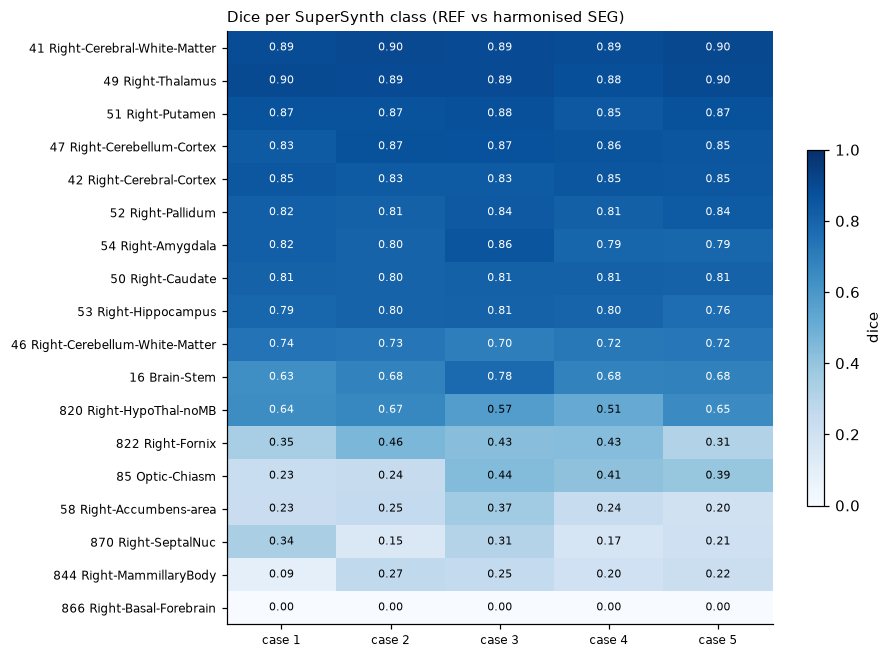

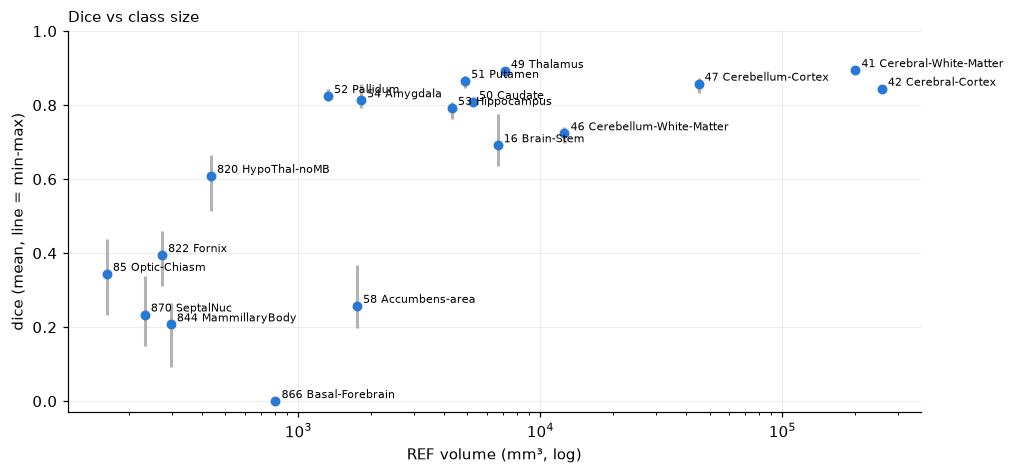

In [4]:
b = labels[labels.presence == 'both']
t = b.pivot_table(index=['label', 'name'], columns='case', values='dice')
t = t.loc[t.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(t.values, cmap='Blues', vmin=0, vmax=1, aspect='auto')
ax.set_yticks(range(len(t)), [f'{l} {n}' for l, n in t.index], fontsize=8)
ax.set_xticks(range(t.shape[1]), [f'case {c}' for c in t.columns], fontsize=8)
ax.grid(False)
for (i, j), v in np.ndenumerate(t.values):
    ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7, color='white' if v > 0.6 else 'black')
ax.set_title('Dice per SuperSynth class (REF vs harmonised SEG)', loc='left', fontsize=10)
fig.colorbar(im, ax=ax, shrink=0.6, label='dice'); plt.show()

fig, ax = plt.subplots(figsize=(10, 4.5))
g = b.groupby(['label', 'name']).agg(v=('vol_ref_mm3', 'mean'), d=('dice', 'mean'), dmin=('dice', 'min'), dmax=('dice', 'max'))
ax.vlines(g.v, g.dmin, g.dmax, color='0.7', lw=2)
ax.scatter(g.v, g.d, color=C_REF, s=30, zorder=3)
for (l, n), r in g.iterrows():
    ax.annotate(f'{l} {n.replace("Right-", "")}', (r.v, r.d), fontsize=7, xytext=(4, 2), textcoords='offset points')
ax.set_xscale('log'); ax.set_ylim(-0.03, 1); ax.set_xlabel('REF volume (mm³, log)'); ax.set_ylabel('dice (mean, line = min-max)')
ax.set_title('Dice vs class size', loc='left', fontsize=10); plt.show()

## 4. Volumes

Each panel compares the volume of every class in the two maps (log-log, diagonal = equal volume). Classes present in
only one map (SEG-only classes such as CSF and the ventricles) are drawn on the border of the panel.

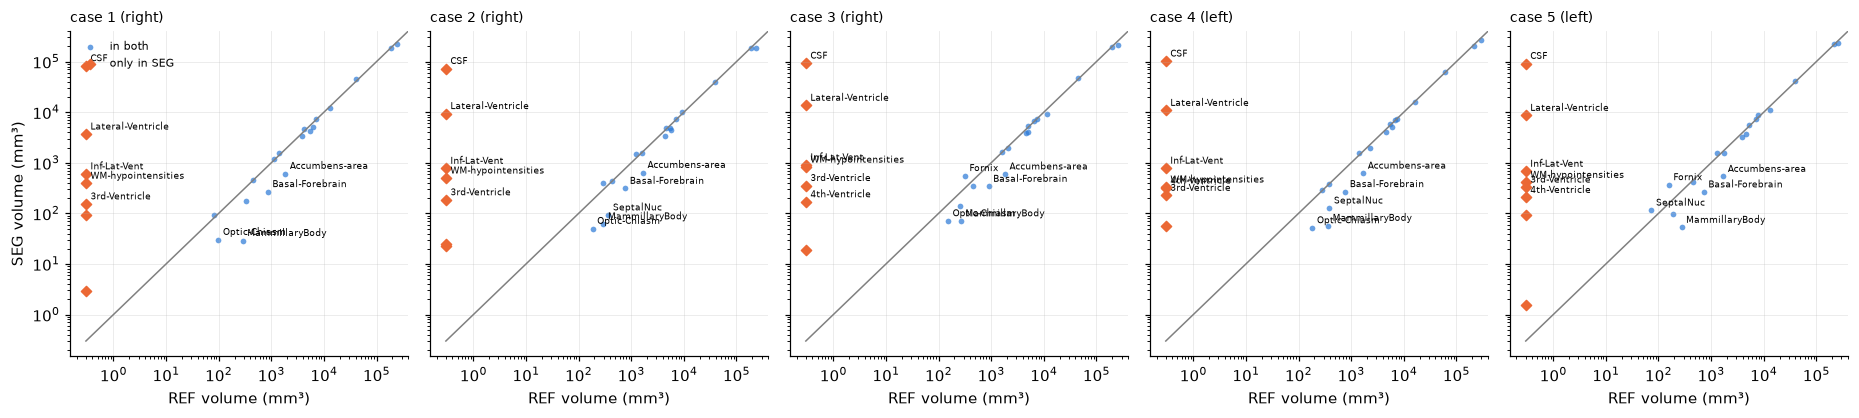

**Relative volume difference per class (mean over cases; `rel_diff` = SEG/REF - 1)**

,,vol_ref,vol_pred,rel_diff_mean,rel_diff_min,rel_diff_max,dice_mean
label,name,,,,,,
844,Right-MammillaryBody,297.190,54.387,-0.814,-0.899,-0.732,0.207
58,Right-Accumbens-area,1747.686,602.816,-0.654,-0.685,-0.615,0.257
866,Right-Basal-Forebrain,804.531,290.714,-0.638,-0.688,-0.596,0.000
85,Optic-Chiasm,161.741,60.454,-0.630,-0.728,-0.483,0.344
822,Right-Fornix,273.446,356.006,0.408,-0.472,1.340,0.395
870,Right-SeptalNuc,232.013,113.190,-0.228,-0.748,0.567,0.234
50,Right-Caudate,5267.891,4287.949,-0.186,-0.229,-0.142,0.808
53,Right-Hippocampus,4311.693,3647.181,-0.153,-0.222,-0.087,0.792
52,Right-Pallidum,1326.874,1501.056,0.134,0.062,0.209,0.825


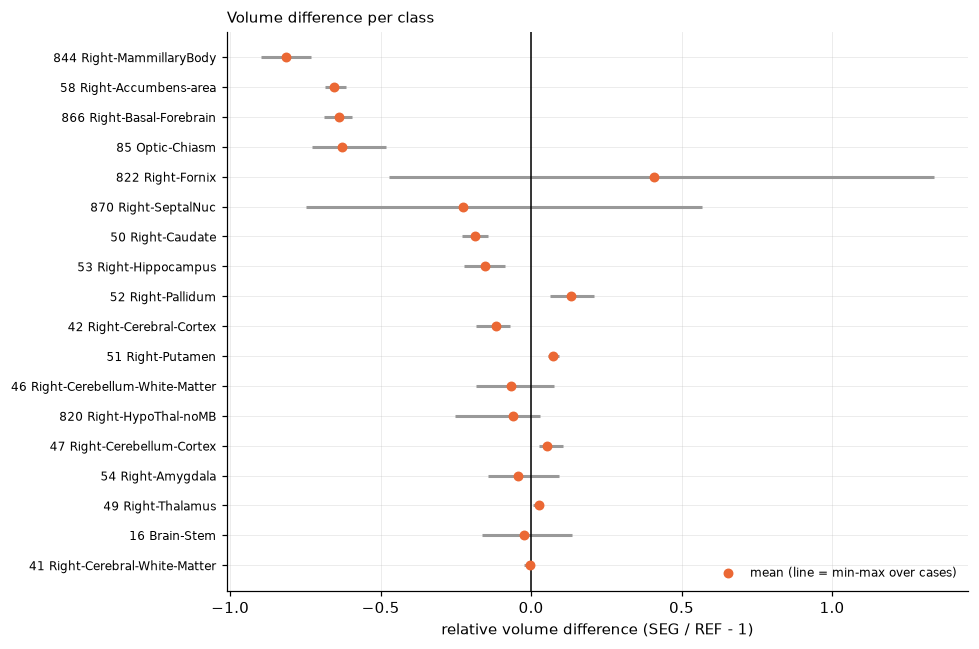

**Total labelled volume per case** (`no_csf` excludes the SEG classes CSF 24, Other-Tissues 907, Bone-Cortical 915)

,vol_ref_mm3,vol_pred_mm3,vol_pred_no_csf_mm3,rel_diff_no_csf
case,,,,
1,518241.945,586483.420,504043.736,-0.027
2,498976.728,538993.690,466257.622,-0.066
3,544375.770,608469.277,515713.688,-0.053
4,620209.821,708872.098,606880.477,-0.021
5,571753.371,647515.871,555826.458,-0.028


In [5]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.9), sharex=True, sharey=True)
lo, hi = 0.3, 4e5
for ax, (case, d) in zip(axes, labels.groupby('case')):
    x, y = d.vol_ref_mm3.clip(lower=lo), d.vol_pred_mm3.clip(lower=lo)
    one = d.presence != 'both'
    ax.plot([lo, hi], [lo, hi], color='0.5', lw=1)
    ax.scatter(x[~one], y[~one], s=14, color=C_REF, alpha=0.7, linewidths=0, label='in both')
    ax.scatter(x[one], y[one], s=22, color=C_PRED, marker='D', label='only in SEG')
    for _, r in d[(one & (d.vol_pred_mm3 > 100)) | (~one & ((d.vol_diff_rel.abs() > 0.5)))].iterrows():
        ax.annotate(r['name'].replace('Right-', '')[:18], (max(r.vol_ref_mm3, lo), max(r.vol_pred_mm3, lo)), fontsize=6,
                    xytext=(3, 3), textcoords='offset points')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(lo / 2, hi); ax.set_ylim(lo / 2, hi)
    ax.set_title(f'case {case} ({summary.seg_side[case]})', fontsize=9, loc='left'); ax.set_xlabel('REF volume (mm³)')
axes[0].set_ylabel('SEG volume (mm³)'); axes[0].legend(frameon=False, fontsize=7, loc='upper left')
plt.tight_layout(); plt.show()

vd = (labels[labels.presence == 'both'].groupby(['label', 'name'])
      .agg(vol_ref=('vol_ref_mm3', 'mean'), vol_pred=('vol_pred_mm3', 'mean'),
           rel_diff_mean=('vol_diff_rel', 'mean'), rel_diff_min=('vol_diff_rel', 'min'), rel_diff_max=('vol_diff_rel', 'max'),
           dice_mean=('dice', 'mean'))
      .assign(abs_rel=lambda t: t.rel_diff_mean.abs()).sort_values('abs_rel', ascending=False).drop(columns='abs_rel'))
vd.to_csv(METRICS / 'volume_differences_over_cases.csv')
display(Markdown('**Relative volume difference per class (mean over cases; `rel_diff` = SEG/REF - 1)**')); display(vd)

top = vd[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
yy = np.arange(len(top))
ax.hlines(yy, top.rel_diff_min, top.rel_diff_max, color='0.6', lw=2)
ax.scatter(top.rel_diff_mean, yy, color=C_PRED, s=30, zorder=3, label='mean (line = min-max over cases)')
ax.axvline(0, color='black', lw=1)
ax.set_yticks(yy, [f'{l} {n}' for l, n in top.index], fontsize=8); ax.set_xlabel('relative volume difference (SEG / REF - 1)')
ax.set_title('Volume difference per class', loc='left', fontsize=10)
ax.legend(frameon=False, fontsize=8, loc='lower right'); plt.tight_layout(); plt.show()

tot = labels.groupby('case')[['vol_ref_mm3', 'vol_pred_mm3']].sum()
inbrain = labels[~labels.label.isin([24, 907, 915])].groupby('case')[['vol_pred_mm3']].sum().rename(columns={'vol_pred_mm3': 'vol_pred_no_csf_mm3'})
tot = tot.join(inbrain); tot['rel_diff_no_csf'] = tot.vol_pred_no_csf_mm3 / tot.vol_ref_mm3 - 1
display(Markdown('**Total labelled volume per case** (`no_csf` excludes the SEG classes CSF 24, Other-Tissues 907, Bone-Cortical 915)')); display(tot)

## 5. Classes present in only one of the maps

All REF classes appear in SEG (no `only_ref`). The SEG-only classes are SuperSynth classes that the conversion never
produces: the ventricles, CSF, WM-hypointensities and non-brain tissue. The second table shows, for each SEG-only
class, which REF class (or background) and which NextBrain (FINE) labels its voxels have.

In [6]:
display(presence)

rows = []
for lab in sorted(presence.label.unique()):
    c = conf[conf.pred == lab].groupby('ref').n.sum()
    f = fine_conf[fine_conf.pred == lab].groupby('fine').n.sum()
    rows.append(dict(label=lab, name=NAMES.get(lab), vol_pred_mm3=c.sum() * 0.064 / 5,
                     from_ref='; '.join(f'{int(k)} {NAMES.get(int(k))} {v / c.sum():.0%}' for k, v in c.sort_values(ascending=False).head(3).items()),
                     from_nextbrain='; '.join(f'{int(k)} {FNAMES.get(int(k))} {v / f.sum():.0%}' for k, v in f.sort_values(ascending=False).head(4).items())))
pres = pd.DataFrame(rows).sort_values('vol_pred_mm3', ascending=False)
pres.to_csv(METRICS / 'seg_only_classes_origin.csv', index=False)
display(Markdown('**SEG-only classes: where their voxels are in REF and in the NextBrain labels (all cases)**'))
display(pres)

,case,label,name,presence,vol_ref_mm3,vol_pred_mm3,ref_to_pred_name,ref_to_pred_frac,pred_from_ref_name,pred_from_ref_frac
0,1,14,3rd-Ventricle,only_pred,0.000,153.344,NaN,NaN,background,0.960
1,1,15,4th-Ventricle,only_pred,0.000,94.464,NaN,NaN,background,0.803
3,1,24,CSF,only_pred,0.000,82436.804,NaN,NaN,background,0.623
6,1,43,Right-Lateral-Ventricle,only_pred,0.000,3681.152,NaN,NaN,background,0.559
7,1,44,Right-Inf-Lat-Vent,only_pred,0.000,602.368,NaN,NaN,Right-Hippocampus,0.373
17,1,77,WM-hypointensities,only_pred,0.000,392.256,NaN,NaN,Right-Cerebral-White-Matter,0.776
24,1,915,Bone-Cortical,only_pred,0.000,2.880,NaN,NaN,background,0.511
25,2,14,3rd-Ventricle,only_pred,0.000,184.832,NaN,NaN,background,0.834
26,2,15,4th-Ventricle,only_pred,0.000,25.280,NaN,NaN,background,0.575
28,2,24,CSF,only_pred,0.000,72713.347,NaN,NaN,Right-Cerebral-Cortex,0.535


**SEG-only classes: where their voxels are in REF and in the NextBrain labels (all cases)**

,label,name,vol_pred_mm3,from_ref,from_nextbrain
2,24,CSF,88284.032,0 background 56%; 42 Right-Cerebral-Corte...,0 background 56%; 2028 ctx-rh-superiorfro...
3,43,Right-Lateral-Ventricle,9228.685,0 background 59%; 41 Right-Cerebral-White...,0 background 59%; 7 white_matter_of_foreb...
4,44,Right-Inf-Lat-Vent,748.698,53 Right-Hippocampus 44%; 41 Right-Cerebr...,354 alveus 35%; 7 white_matter_of_forebra...
5,77,WM-hypointensities,489.549,41 Right-Cerebral-White-Matter 85%; 0 bac...,7 white_matter_of_forebrain 85%; 0 backgr...
0,14,3rd-Ventricle,249.600,0 background 86%; 820 Right-HypoThal-noMB...,0 background 86%; 275 posterior_hypothala...
1,15,4th-Ventricle,162.189,0 background 77%; 47 Right-Cerebellum-Cor...,0 background 77%; 580 pons 6%; 595 molecu...
7,915,Bone-Cortical,38.131,0 background 65%; 41 Right-Cerebral-White...,0 background 65%; 7 white_matter_of_foreb...
6,907,Other-Tissues,0.307,0 background 50%; 41 Right-Cerebral-White...,0 background 50%; 7 white_matter_of_foreb...


## 6. Classes in the wrong position

Same definition as in `simplifiednxb`: present in both maps, dice < 0.2 **and** SEG centroid outside the sphere with
the REF volume. Also `relabelled` (REF voxels mostly go to another class *and* SEG voxels mostly come from another
class) and mutual swaps.

,shared,misplaced,relabelled
case,,,
1,18,2,1
2,18,1,2
3,18,1,1
4,18,2,3
5,18,2,3


mutual swaps found: 0


,case,label_a,name_a,label_b,name_b,frac_a_to_b,frac_b_to_a,dice_a,dice_b


**Position per class (mean over cases, sorted by dice)**

,,dice,shift_mm,r_eq_mm,n_misplaced,n_relabelled,goes_to,goes_frac,comes_from,comes_frac
label,name,,,,,,,,,
866,Right-Basal-Forebrain,0.000,19.489,5.766,5,5,Right-Cerebral-White-Matter,0.647,Right-Cerebral-White-Matter,0.744
844,Right-MammillaryBody,0.207,4.204,4.134,1,0,Right-Cerebral-White-Matter,0.388,Right-MammillaryBody,0.660
870,Right-SeptalNuc,0.234,3.758,3.631,1,3,Right-Lateral-Ventricle,0.409,Right-Cerebral-White-Matter,0.521
58,Right-Accumbens-area,0.257,21.824,7.471,1,2,Right-Cerebral-White-Matter,0.353,Right-Accumbens-area,0.515
85,Optic-Chiasm,0.344,3.587,3.360,0,0,CSF,0.564,Optic-Chiasm,0.652
822,Right-Fornix,0.395,9.508,3.999,0,0,Right-Fornix,0.517,Right-Fornix,0.477
820,Right-HypoThal-noMB,0.609,1.044,4.700,0,0,Right-HypoThal-noMB,0.590,Right-HypoThal-noMB,0.632
16,Brain-Stem,0.691,3.430,11.651,0,0,Brain-Stem,0.684,Brain-Stem,0.702
46,Right-Cerebellum-White-Matter,0.724,3.597,14.374,0,0,Right-Cerebellum-White-Matter,0.700,Right-Cerebellum-White-Matter,0.752


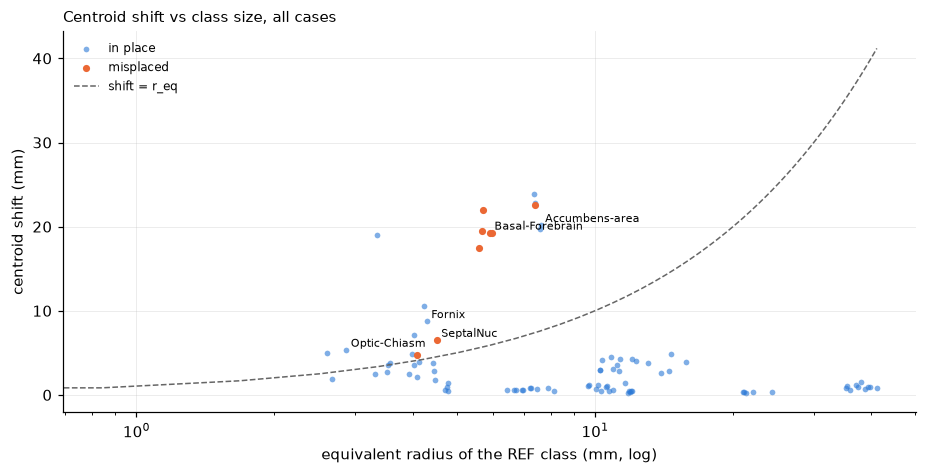

In [7]:
cnt = labels.groupby('case').agg(shared=('presence', lambda p: (p == 'both').sum()), misplaced=('misplaced', 'sum'),
                                 relabelled=('relabelled', 'sum'))
display(cnt)
print('mutual swaps found:', len(swaps)); display(swaps)

cols = ['label', 'name', 'dice', 'vol_ref_mm3', 'vol_pred_mm3', 'centroid_dist_mm', 'r_eq_mm',
        'ref_to_pred_name', 'ref_to_pred_frac', 'pred_from_ref_name', 'pred_from_ref_frac', 'misplaced', 'relabelled']
pos = (labels[labels.presence == 'both'].groupby(['label', 'name'])
       .agg(dice=('dice', 'mean'), shift_mm=('centroid_dist_mm', 'mean'), r_eq_mm=('r_eq_mm', 'mean'),
            n_misplaced=('misplaced', 'sum'), n_relabelled=('relabelled', 'sum'),
            goes_to=('ref_to_pred_name', lambda s: s.mode().iat[0]), goes_frac=('ref_to_pred_frac', 'mean'),
            comes_from=('pred_from_ref_name', lambda s: s.mode().iat[0]), comes_frac=('pred_from_ref_frac', 'mean'))
       .sort_values('dice'))
pos.to_csv(METRICS / 'position_over_cases.csv')
display(Markdown('**Position per class (mean over cases, sorted by dice)**')); display(pos)

fig, ax = plt.subplots(figsize=(10, 4.5))
s = labels[labels.presence == 'both']
ax.scatter(s.r_eq_mm, s.centroid_dist_mm, s=14, alpha=0.6, color=C_REF, linewidths=0, label='in place')
m = s[s.misplaced]
ax.scatter(m.r_eq_mm, m.centroid_dist_mm, s=22, color=C_PRED, linewidths=0, label='misplaced')
r = np.linspace(0, s.r_eq_mm.max(), 50); ax.plot(r, r, color='0.4', lw=1, ls='--', label='shift = r_eq')
for _, row in s[s.centroid_dist_mm > 5].drop_duplicates('label').iterrows():
    ax.annotate(row['name'].replace('Right-', ''), (row.r_eq_mm, row.centroid_dist_mm), fontsize=7, xytext=(3, 2), textcoords='offset points')
ax.set_xscale('log'); ax.set_xlabel('equivalent radius of the REF class (mm, log)'); ax.set_ylabel('centroid shift (mm)')
ax.legend(frameon=False, fontsize=8); ax.set_title('Centroid shift vs class size, all cases', loc='left', fontsize=10)
plt.show()

## 7. Where do the disagreements come from? (audit of the NextBrain -> SuperSynth mapping)

REF is a relabelling of FINE (the NextBrain labels), so every NextBrain label has an *expected* SuperSynth class (the
one the conversion gave it). For each NextBrain label we measure the fraction of its voxels that SEG puts in that class
(`frac_ok`) and where most of the rest goes.

* A large NextBrain label with a **moderate** `frac_ok` (0.7-0.9) loses voxels at its border: normal segmentation error.
* A NextBrain label with `frac_ok` close to **0 in every case** is a structure that SuperSynth systematically assigns to
  another class: the conversion put it in a class that does not correspond to SuperSynth's definition. These are
  **mapping problems**, and they explain the low dice of several classes.

In [8]:
og = (origin.groupby(['fine', 'fine_name'])
      .agg(expected=('expected_name', 'first'), n_cases=('case', 'size'), vol_mm3=('vol_mm3', 'mean'),
           vol_wrong_mm3=('vol_wrong_mm3', 'mean'), frac_ok=('frac_ok', 'mean'),
           frac_ok_min=('frac_ok', 'min'), frac_ok_max=('frac_ok', 'max'),
           seg_class_instead=('main_wrong_name', lambda s: s.mode().iat[0] if s.notna().any() else None),
           frac_instead=('main_wrong_frac', 'mean'))
      .reset_index())
og.to_csv(METRICS / 'disagreement_origin_over_cases.csv', index=False)

display(Markdown('**Per REF class: fraction of its voxels that SEG agrees with, and the NextBrain labels with the most disagreeing volume**'))
rows = []
for cls, g in og.groupby('expected'):
    tot, wrong = g.vol_mm3.sum(), g.vol_wrong_mm3.sum()
    worst = g.sort_values('vol_wrong_mm3', ascending=False).head(4)
    rows.append(dict(ref_class=cls, n_nextbrain_labels=len(g), vol_mm3=tot, frac_ok=1 - wrong / tot,
                     main_sources_of_error='; '.join(f'{int(r.fine)} {r.fine_name} ({r.vol_wrong_mm3:.0f} mm³ -> {r.seg_class_instead})'
                                                     for _, r in worst.iterrows())))
per_class = pd.DataFrame(rows).sort_values('frac_ok')
per_class.to_csv(METRICS / 'disagreement_origin_per_class.csv', index=False)
display(per_class)

mapping_problems = og[(og.frac_ok < 0.3) & (og.vol_mm3 > 20)].sort_values('vol_mm3', ascending=False)
mapping_problems.to_csv(METRICS / 'mapping_problems.csv', index=False)
display(Markdown(f'**NextBrain labels > 20 mm³ that SEG almost never puts in their REF class** (`frac_ok` < 0.3, mean over cases): '
                 f'{len(mapping_problems)} labels, {mapping_problems.vol_mm3.sum():.0f} mm³ per case'))
display(mapping_problems)

**Per REF class: fraction of its voxels that SEG agrees with, and the NextBrain labels with the most disagreeing volume**

,ref_class,n_nextbrain_labels,vol_mm3,frac_ok,main_sources_of_error
4,Right-Basal-Forebrain,6,804.531,0.000,310 substantia_nigra__reticular_part (289...
13,Right-MammillaryBody,9,297.190,0.124,275 posterior_hypothalamic_nucleus (121 m...
16,Right-SeptalNuc,1,232.013,0.160,103 medial_septal_nucleus (195 mm³ -> Rig...
2,Right-Accumbens-area,8,1747.686,0.174,384 midbrain_(mesencephalon) (935 mm³ -> ...
1,Optic-Chiasm,2,161.741,0.244,161 optic_chiasm (69 mm³ -> CSF); 114 opt...
10,Right-Fornix,1,273.446,0.463,199 fornix (147 mm³ -> Right-Lateral-Vent...
12,Right-HypoThal-noMB,22,435.712,0.592,309 lenticular_fasciculus (42 mm³ -> Righ...
0,Brain-Stem,14,6664.758,0.688,414 pontine_nucleus (1101 mm³ -> CSF); 66...
7,Right-Cerebellum-White-Matter,5,12581.376,0.699,611 white_matter_of_hindbrain (3729 mm³ -...
11,Right-Hippocampus,54,4320.096,0.732,354 alveus (673 mm³ -> Right-Cerebral-Whi...


**NextBrain labels > 20 mm³ that SEG almost never puts in their REF class** (`frac_ok` < 0.3, mean over cases): 26 labels, 4684 mm³ per case

,fine,fine_name,expected,n_cases,vol_mm3,vol_wrong_mm3,frac_ok,frac_ok_min,frac_ok_max,seg_class_instead,frac_instead
135,384,midbrain_(mesencephalon),Right-Accumbens-area,5,934.822,934.822,0.000,0.000,0.000,Brain-Stem,0.501
117,354,alveus,Right-Hippocampus,5,917.683,672.794,0.272,0.225,0.392,Right-Cerebral-White-Matter,0.340
28,184,stria_terminalis,Right-Caudate,5,314.842,300.467,0.053,0.001,0.113,Right-Cerebral-White-Matter,0.425
95,310,substantia_nigra__reticular_part,Right-Basal-Forebrain,5,289.024,289.024,0.000,0.000,0.000,Right-Cerebral-White-Matter,0.639
2,68,septum_pellucidum,Right-Cerebral-White-Matter,5,248.986,226.304,0.067,0.011,0.100,Right-Lateral-Ventricle,0.746
8,103,medial_septal_nucleus,Right-SeptalNuc,5,232.013,194.918,0.215,0.092,0.368,Right-Lateral-Ventricle,0.366
39,208,optic_tract,Right-Accumbens-area,5,231.539,231.539,0.000,0.000,0.000,Right-Cerebral-White-Matter,0.794
13,117,bed_nucleus_of_stria_terminalis,Right-Cerebral-White-Matter,5,228.224,191.872,0.175,0.065,0.279,Right-Caudate,0.305
136,385,red_nucleus,Right-Basal-Forebrain,5,212.634,212.634,0.000,0.000,0.000,Right-Cerebral-White-Matter,0.696
137,393,tail_of_caudate,Right-Caudate,5,199.782,199.782,0.000,0.000,0.000,Right-Cerebral-White-Matter,0.482


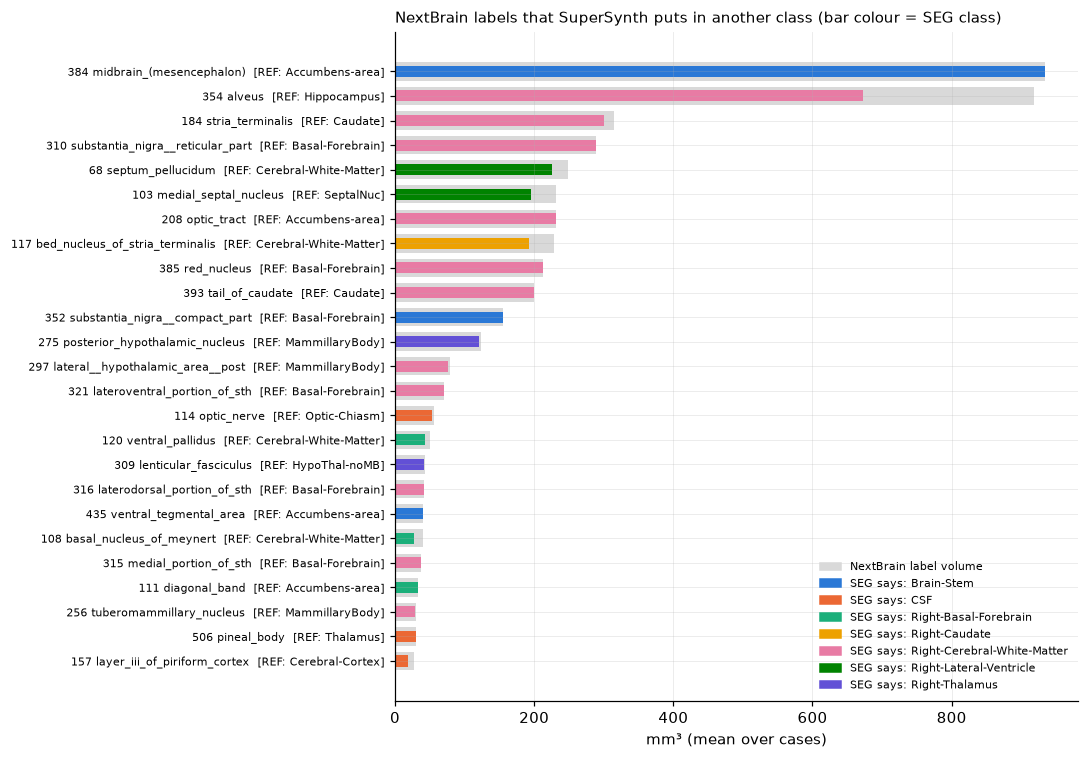

In [9]:
mp = mapping_problems.head(25)[::-1]
cls = sorted(mp.seg_class_instead.unique())
palette = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
col = {c: palette[i % len(palette)] for i, c in enumerate(cls)}
fig, ax = plt.subplots(figsize=(10, 7))
yy = np.arange(len(mp))
ax.barh(yy, mp.vol_mm3, color='0.85', height=0.75, label='NextBrain label volume')
ax.barh(yy, mp.vol_wrong_mm3, color=[col[c] for c in mp.seg_class_instead], height=0.45)
ax.set_yticks(yy, [f'{int(f)} {n[:32]}  [REF: {e.replace("Right-", "")}]' for f, n, e in zip(mp.fine, mp.fine_name, mp.expected)], fontsize=7)
from matplotlib.patches import Patch
handles = [Patch(color='0.85', label='NextBrain label volume')] + [Patch(color=col[c], label=f'SEG says: {c}') for c in cls]
ax.set_xlabel('mm³ (mean over cases)'); ax.legend(handles=handles, frameon=False, fontsize=7, loc='lower right')
ax.set_title('NextBrain labels that SuperSynth puts in another class (bar colour = SEG class)', loc='left', fontsize=10)
plt.tight_layout(); plt.show()

## 8. Visual inspection

The image is the synthetic input. Rows: (1) contours of the class in REF (**blue**) and SEG (**orange**);
(2) REF classes; (3) SEG classes (harmonised, FreeSurfer colours); (4) FINE NextBrain labels with the contour of the
REF class, to see which NextBrain structures the class is made of. Views cut through the REF centroid.

In [10]:
_cache = {}
def vols(case):
    if case not in _cache:
        ref, seg, _, affine, _ = cs.load_case(case)
        fine = cs.load_fine(case)
        img = np.asanyarray(nib.load(cs.paths(case)['img']).dataobj).astype(np.float32)
        img = img[..., 0] if img.ndim == 4 else img
        _cache.clear(); _cache[case] = (img, ref, seg, fine, affine)
    return _cache[case]

def _lut_array(path):
    a = np.full((3000, 3), 0.5)
    for line in open(path):
        p = line.split()
        if len(p) >= 5 and p[0].isdigit() and int(p[0]) < 3000:
            a[int(p[0])] = np.array(p[2:5], float) / 255
    a[0] = 0
    return a
LUT_SS, LUT_NXB = _lut_array(cs.FS_LUT), _lut_array(cs.NXB_LUT)

def _plane(a, axis, idx):
    return np.take(a, idx, axis=axis).T

def _norm(im):
    lo, hi = np.percentile(im[im > 0], [1, 99]) if (im > 0).any() else (0, 1)
    return np.clip((im - lo) / (hi - lo + 1e-6), 0, 1)

def show_label(case, label, pad_mm=12, title=None):
    img, ref, seg, fine, affine = vols(case)
    mr, mp_ = ref == label, seg == label
    c = np.round(np.argwhere(mr if mr.any() else mp_).mean(0)).astype(int)
    both = np.argwhere(mr | mp_)
    pad = int(pad_mm / 0.4)
    lo, hi = np.maximum(both.min(0) - pad, 0), np.minimum(both.max(0) + pad, np.array(ref.shape) - 1)
    fig, axes = plt.subplots(4, 3, figsize=(12, 14.5))
    for col, (axis, view) in enumerate([(0, 'sagittal'), (1, 'coronal'), (2, 'axial')]):
        keep = [a for a in range(3) if a != axis]
        sl = [slice(None)] * 3
        sl[keep[0]] = slice(lo[keep[0]], hi[keep[0]] + 1); sl[keep[1]] = slice(lo[keep[1]], hi[keep[1]] + 1)
        sl[axis] = c[axis]
        im, r, p, f = img[tuple(sl)].T, ref[tuple(sl)].T, seg[tuple(sl)].T, fine[tuple(sl)].T
        ax = axes[0, col]
        ax.imshow(_norm(im), cmap='gray', origin='lower')
        ax.contour(r == label, [0.5], colors=[C_REF], linewidths=1.6)
        ax.contour(p == label, [0.5], colors=[C_PRED], linewidths=1.6)
        ax.set_title(f'{view} (slice {c[axis]})  blue=REF  orange=SEG', fontsize=8, loc='left')
        for row, (lab, lut, nm) in enumerate([(r, LUT_SS, 'REF classes'), (p, LUT_SS, 'SEG classes'), (f, LUT_NXB, 'FINE NextBrain labels')], start=1):
            ax = axes[row, col]
            ax.imshow(_norm(im), cmap='gray', origin='lower')
            ax.imshow(lut[np.clip(lab, 0, 2999)], origin='lower', alpha=0.55)
            ax.contour((p if row == 2 else r) == label, [0.5], colors=['white'], linewidths=1.2)
            ax.set_title(f'{nm} (white = {"SEG" if row == 2 else "REF"} {label})', fontsize=8, loc='left')
    for ax in axes.flat:
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    row = labels[(labels.case == case) & (labels.label == label)].iloc[0]
    fig.suptitle(title or (f'case {case} - {label} {NAMES.get(label, "?")}:  dice {row.dice:.2f}, '
                           f'vol REF {row.vol_ref_mm3:.0f} / SEG {row.vol_pred_mm3:.0f} mm³, shift {row.centroid_dist_mm:.1f} mm, '
                           f'REF -> {row.ref_to_pred_name} ({row.ref_to_pred_frac:.0%}), SEG <- {row.pred_from_ref_name} ({row.pred_from_ref_frac:.0%})'),
                 fontsize=9, x=0.01, ha='left')
    plt.tight_layout(); plt.show()

def composition(label, case=None):
    # NextBrain labels inside a REF class (volume per case) and what SEG says about them
    o = origin[(origin.expected_class == label) & ((origin.case == case) if case else True)]
    return (o.groupby(['fine', 'fine_name']).agg(vol_mm3=('vol_mm3', 'mean'), frac_ok=('frac_ok', 'mean'),
                                                 seg_class_instead=('main_wrong_name', lambda s: s.mode().iat[0] if s.notna().any() else None))
            .sort_values('vol_mm3', ascending=False))

### 8.1 Classes with the lowest dice

,label,name,dice,shift_mm,goes_to,comes_from
0,866,Right-Basal-Forebrain,0.000,19.489,Right-Cerebral-White-Matter,Right-Cerebral-White-Matter
1,844,Right-MammillaryBody,0.207,4.204,Right-Cerebral-White-Matter,Right-MammillaryBody
2,870,Right-SeptalNuc,0.234,3.758,Right-Lateral-Ventricle,Right-Cerebral-White-Matter
3,58,Right-Accumbens-area,0.257,21.824,Right-Cerebral-White-Matter,Right-Accumbens-area
4,85,Optic-Chiasm,0.344,3.587,CSF,Optic-Chiasm
5,822,Right-Fornix,0.395,9.508,Right-Fornix,Right-Fornix


**866 Right-Basal-Forebrain: NextBrain labels it is made of (REF) and what SEG says about them**

,,vol_mm3,frac_ok,seg_class_instead
fine,fine_name,,,
310,substantia_nigra__reticular_part,289.024,0.000,Right-Cerebral-White-Matter
385,red_nucleus,212.634,0.000,Right-Cerebral-White-Matter
352,substantia_nigra__compact_part,155.200,0.000,Brain-Stem
321,lateroventral_portion_of_sth,69.811,0.000,Right-Cerebral-White-Matter
316,laterodorsal_portion_of_sth,40.960,0.000,Right-Cerebral-White-Matter
315,medial_portion_of_sth,36.902,0.000,Right-Cerebral-White-Matter


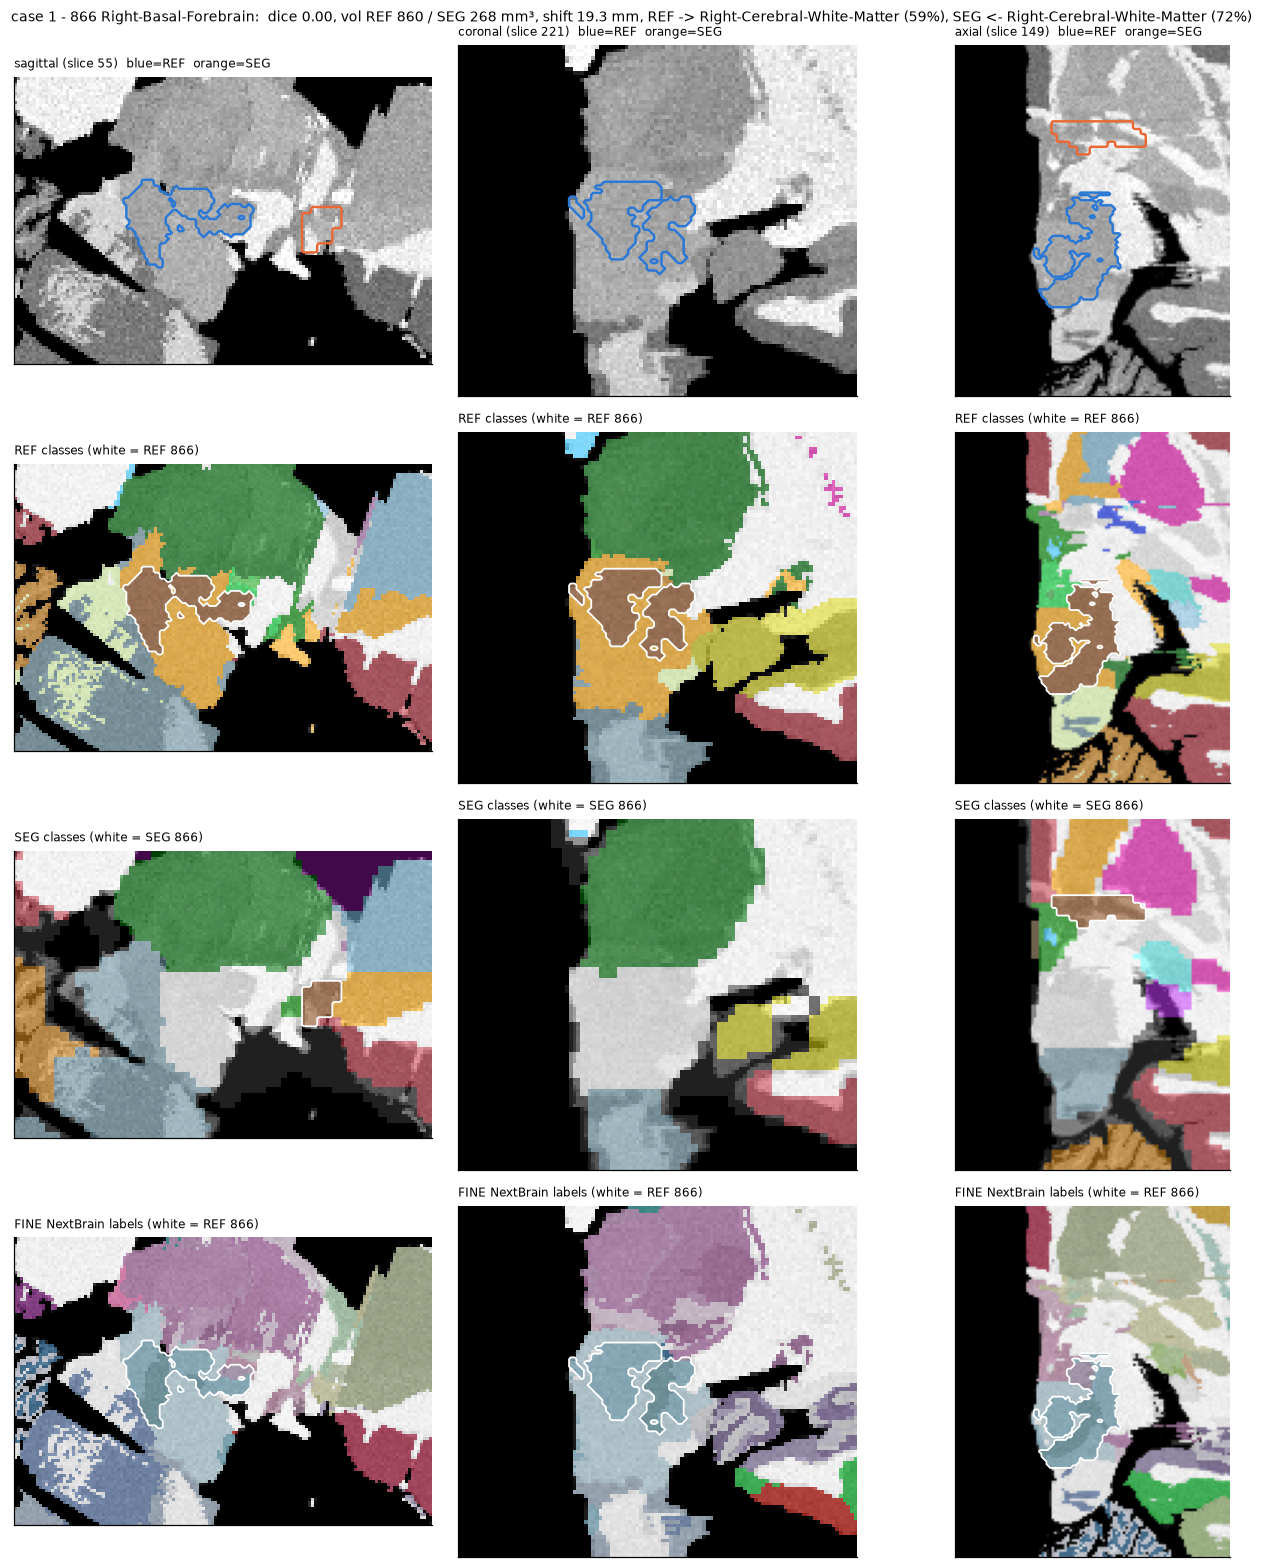

**844 Right-MammillaryBody: NextBrain labels it is made of (REF) and what SEG says about them**

,,vol_mm3,frac_ok,seg_class_instead
fine,fine_name,,,
275,posterior_hypothalamic_nucleus,123.571,0.020,Right-Thalamus
297,lateral__hypothalamic_area__posterior_part,79.270,0.032,Right-Cerebral-White-Matter
256,tuberomammillary_nucleus,30.016,0.029,Right-Cerebral-White-Matter
298,mammillary_peduncle,23.219,0.443,Right-Cerebral-White-Matter
306,medial_part_of_medial_mammillary_nucleus,14.733,0.598,Right-Cerebral-White-Matter
305,lateral_part_of_medial_mammillary_nucleus,11.277,0.497,Right-Cerebral-White-Matter
307,basal_division_of_medial_mammillary_nucleus,10.470,0.572,Right-Cerebral-White-Matter
308,lateral_mammillary_nucleus,2.893,0.154,CSF
304,supramammillary_nucleus,1.741,0.229,Right-Cerebral-White-Matter


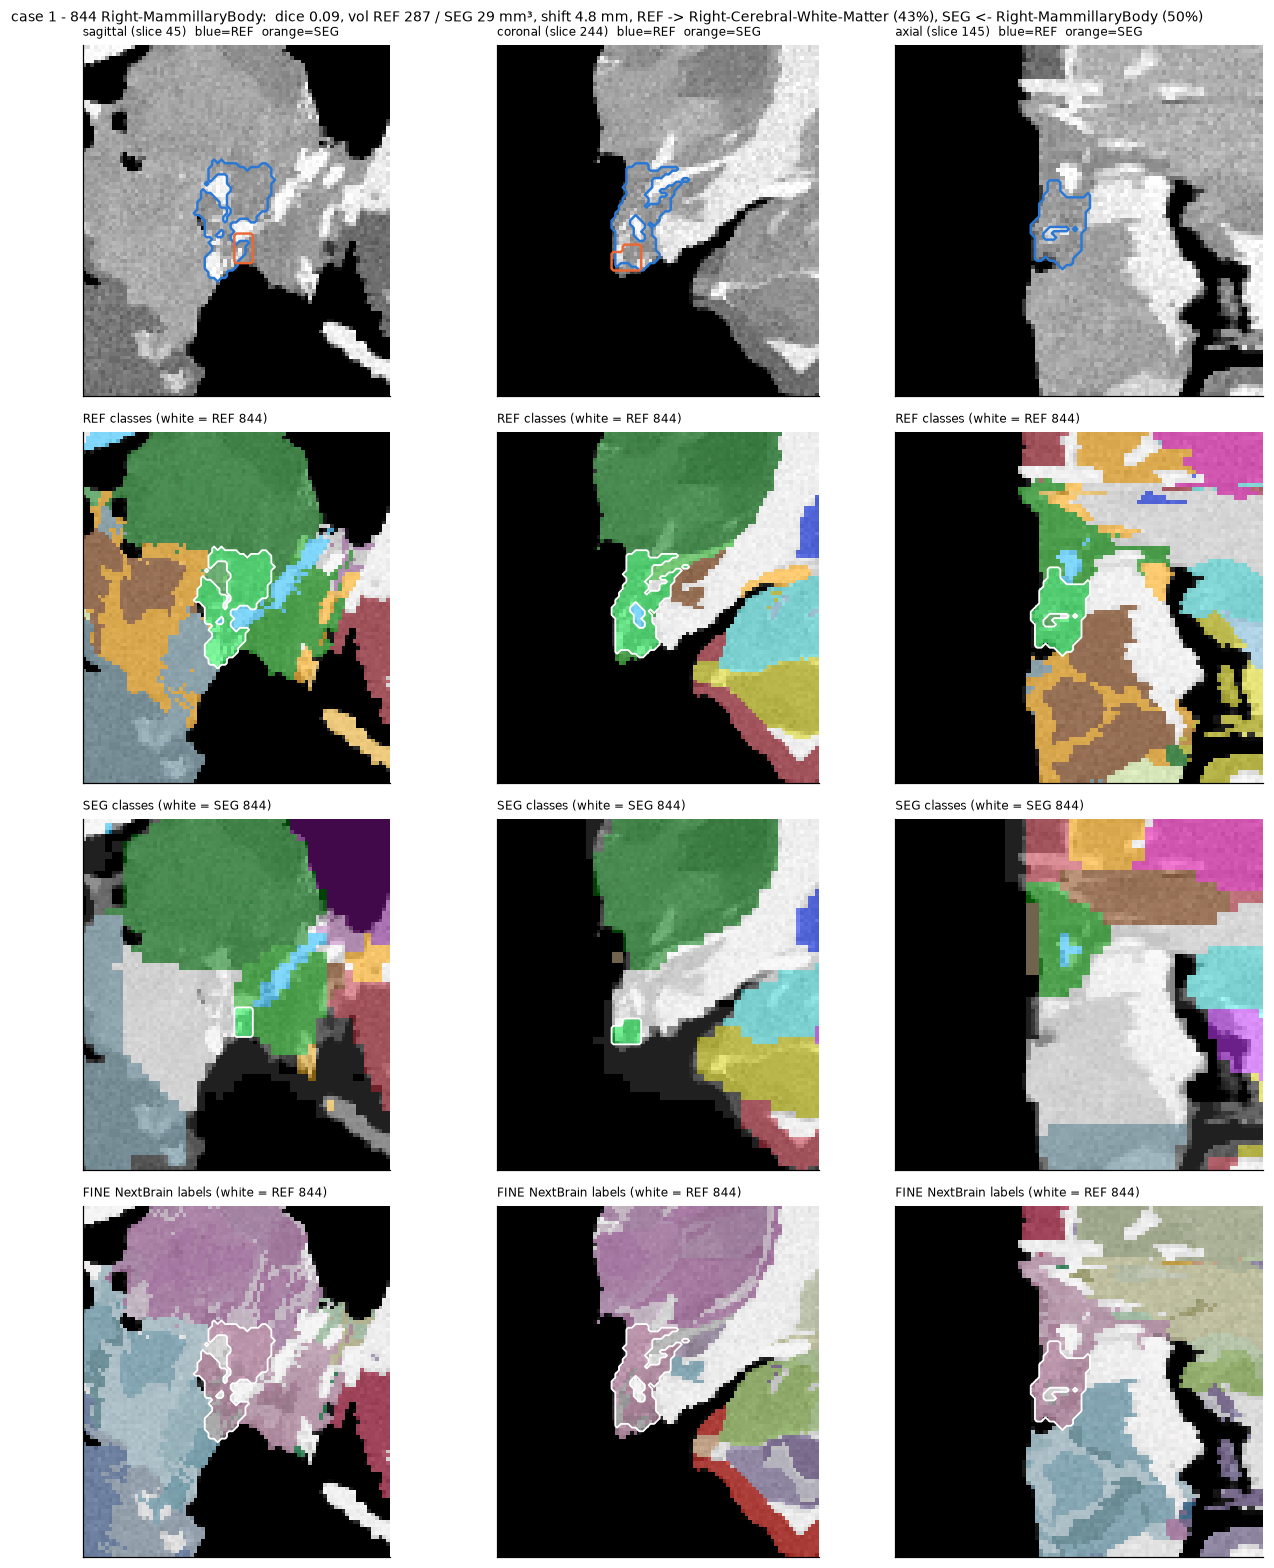

**870 Right-SeptalNuc: NextBrain labels it is made of (REF) and what SEG says about them**

,,vol_mm3,frac_ok,seg_class_instead
fine,fine_name,,,
103,medial_septal_nucleus,232.013,0.215,Right-Lateral-Ventricle


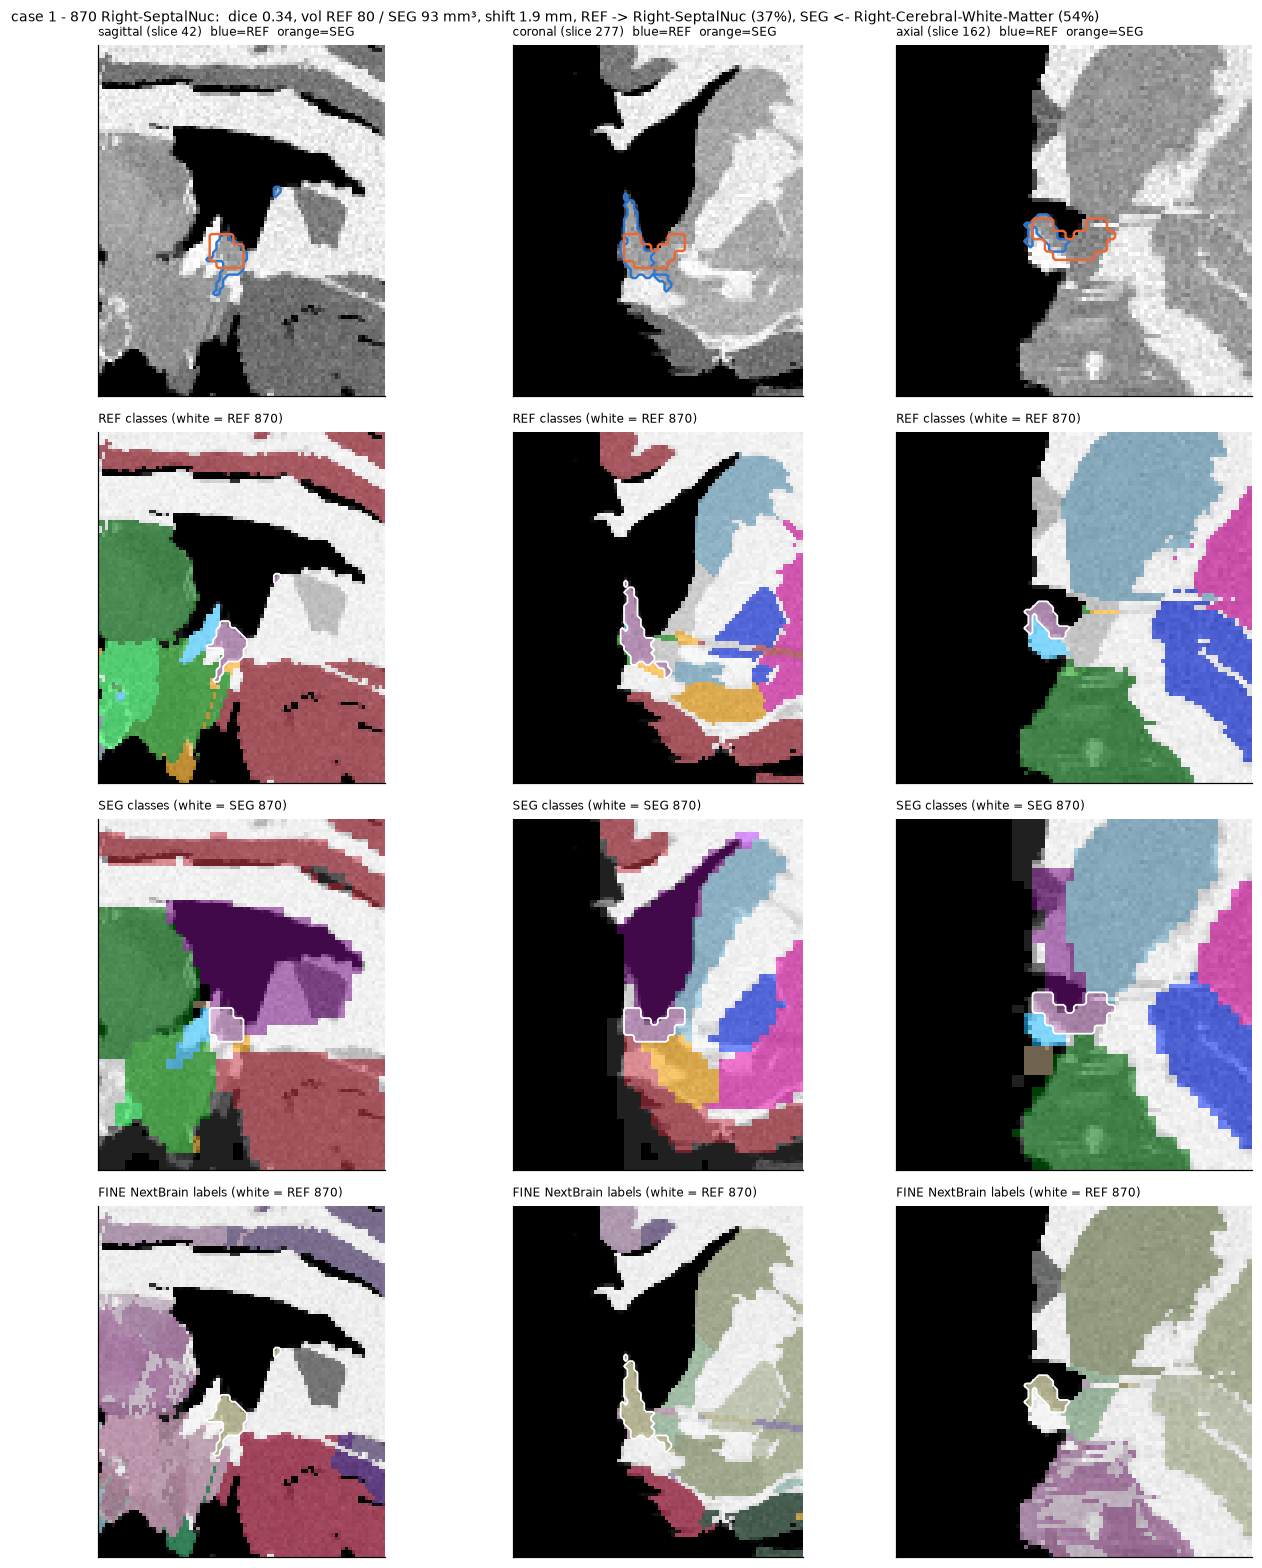

**58 Right-Accumbens-area: NextBrain labels it is made of (REF) and what SEG says about them**

,,vol_mm3,frac_ok,seg_class_instead
fine,fine_name,,,
384,midbrain_(mesencephalon),934.822,0.000,Brain-Stem
101,core_of_nucleus_accumbens,466.893,0.651,Right-Putamen
208,optic_tract,231.539,0.000,Right-Cerebral-White-Matter
435,ventral_tegmental_area,39.744,0.000,Brain-Stem
111,diagonal_band,33.421,0.018,Right-Basal-Forebrain
843,infundibular_stalk,21.184,0.000,CSF
412,fasciculus_retroflexus_(habenuno-interpeduncular_tract),10.112,0.000,Right-Thalamus
498,peripeduncular_nucleus,9.971,0.000,Right-Cerebral-White-Matter


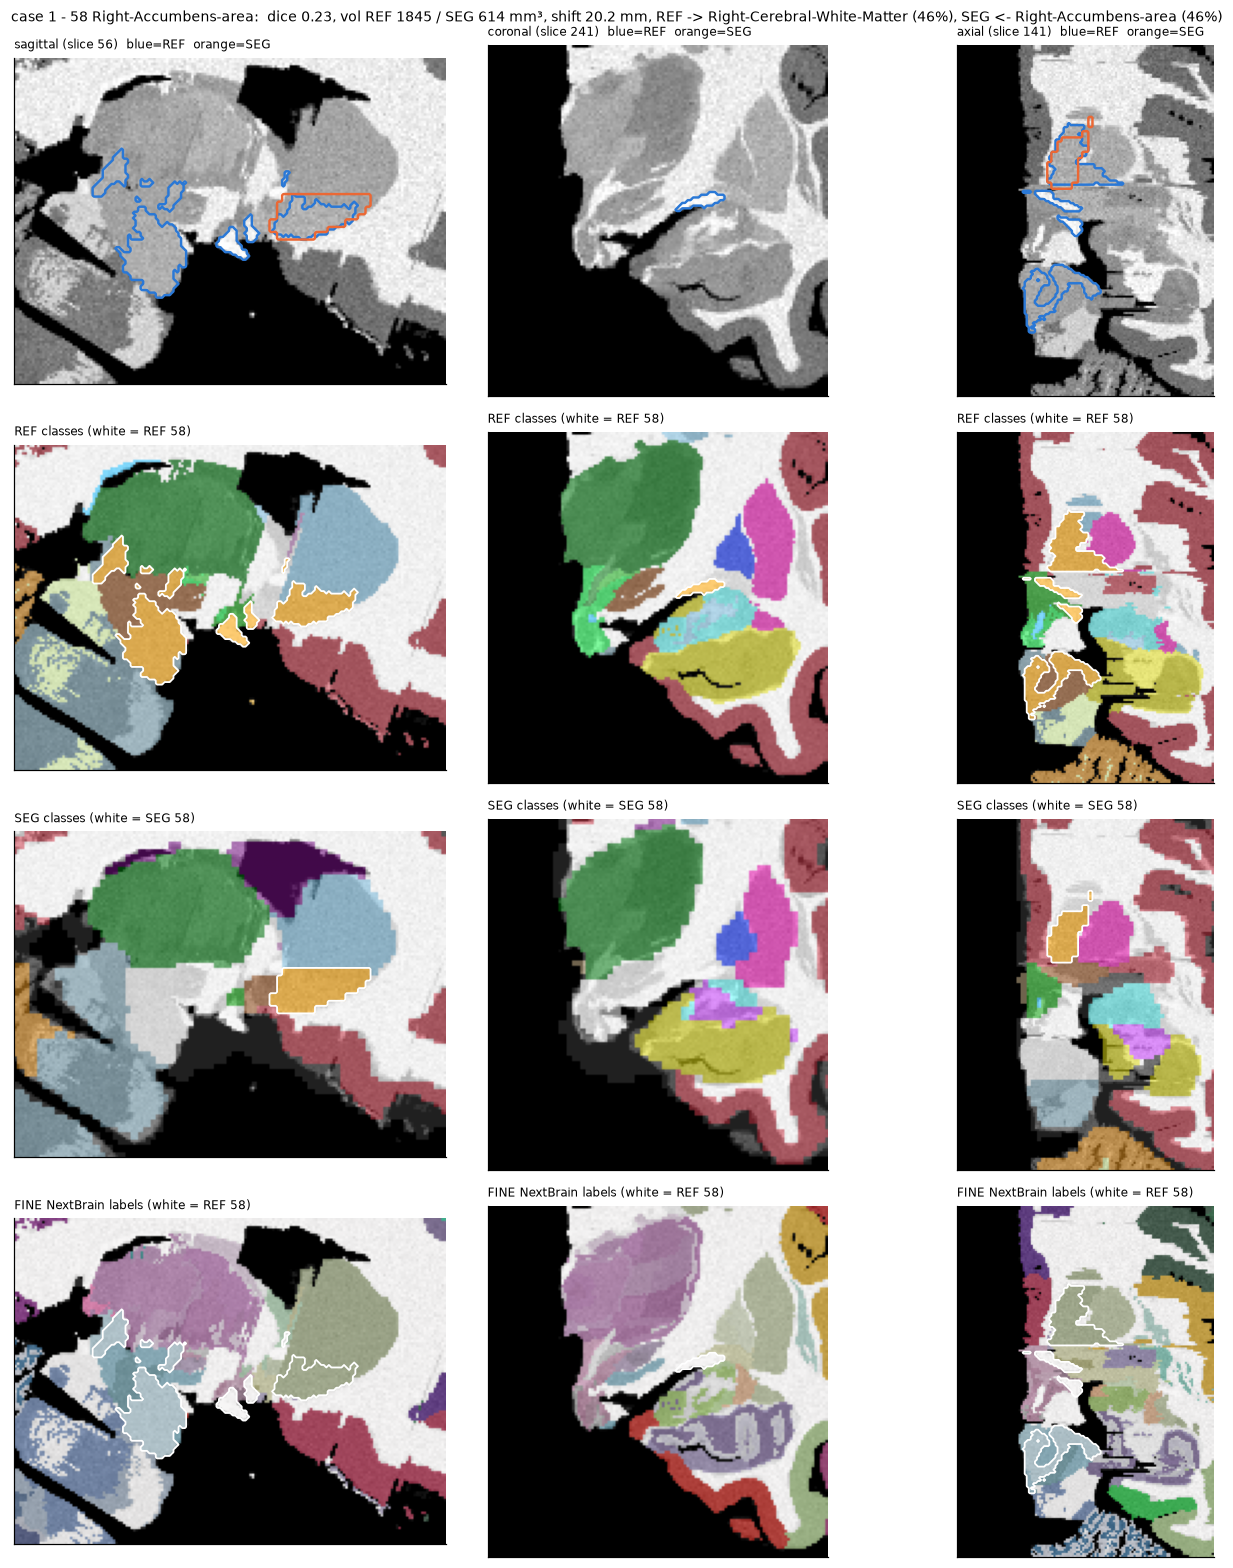

**85 Optic-Chiasm: NextBrain labels it is made of (REF) and what SEG says about them**

,,vol_mm3,frac_ok,seg_class_instead
fine,fine_name,,,
161,optic_chiasm,105.741,0.347,CSF
114,optic_nerve,56.000,0.028,CSF


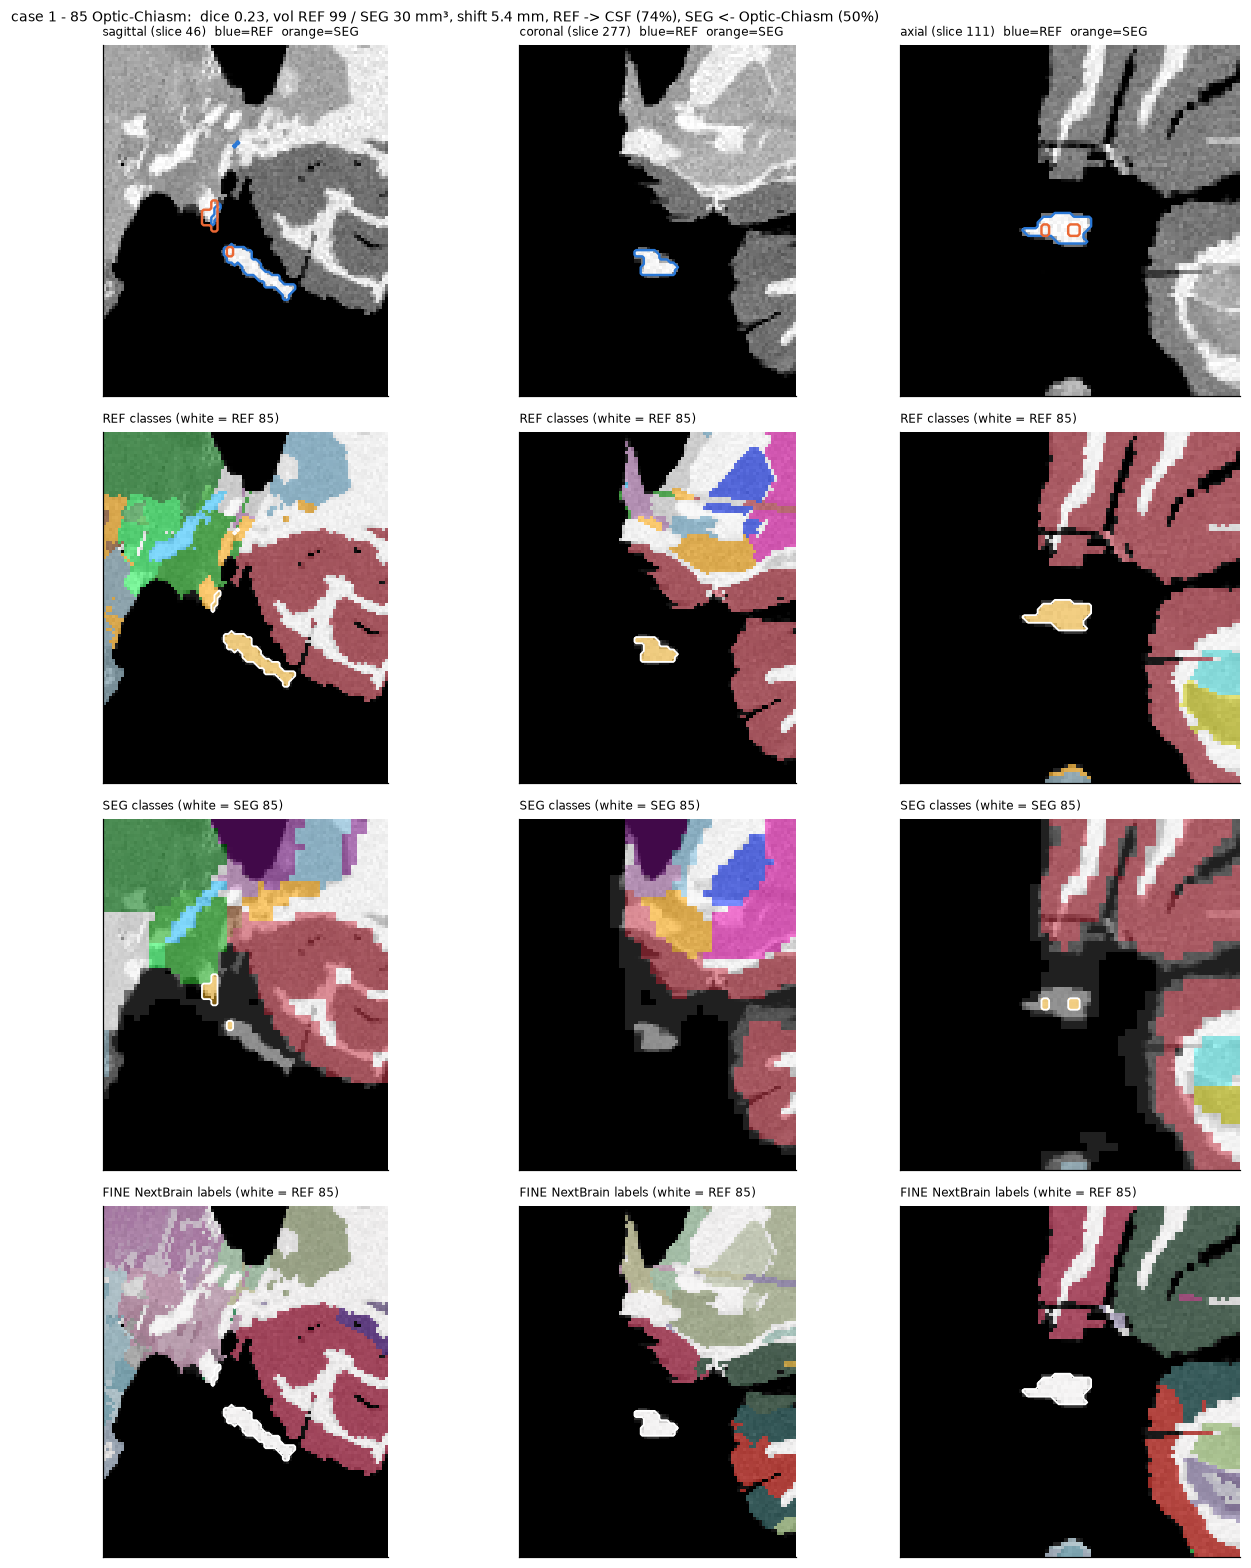

**822 Right-Fornix: NextBrain labels it is made of (REF) and what SEG says about them**

,,vol_mm3,frac_ok,seg_class_instead
fine,fine_name,,,
199,fornix,273.446,0.471,Right-Lateral-Ventricle


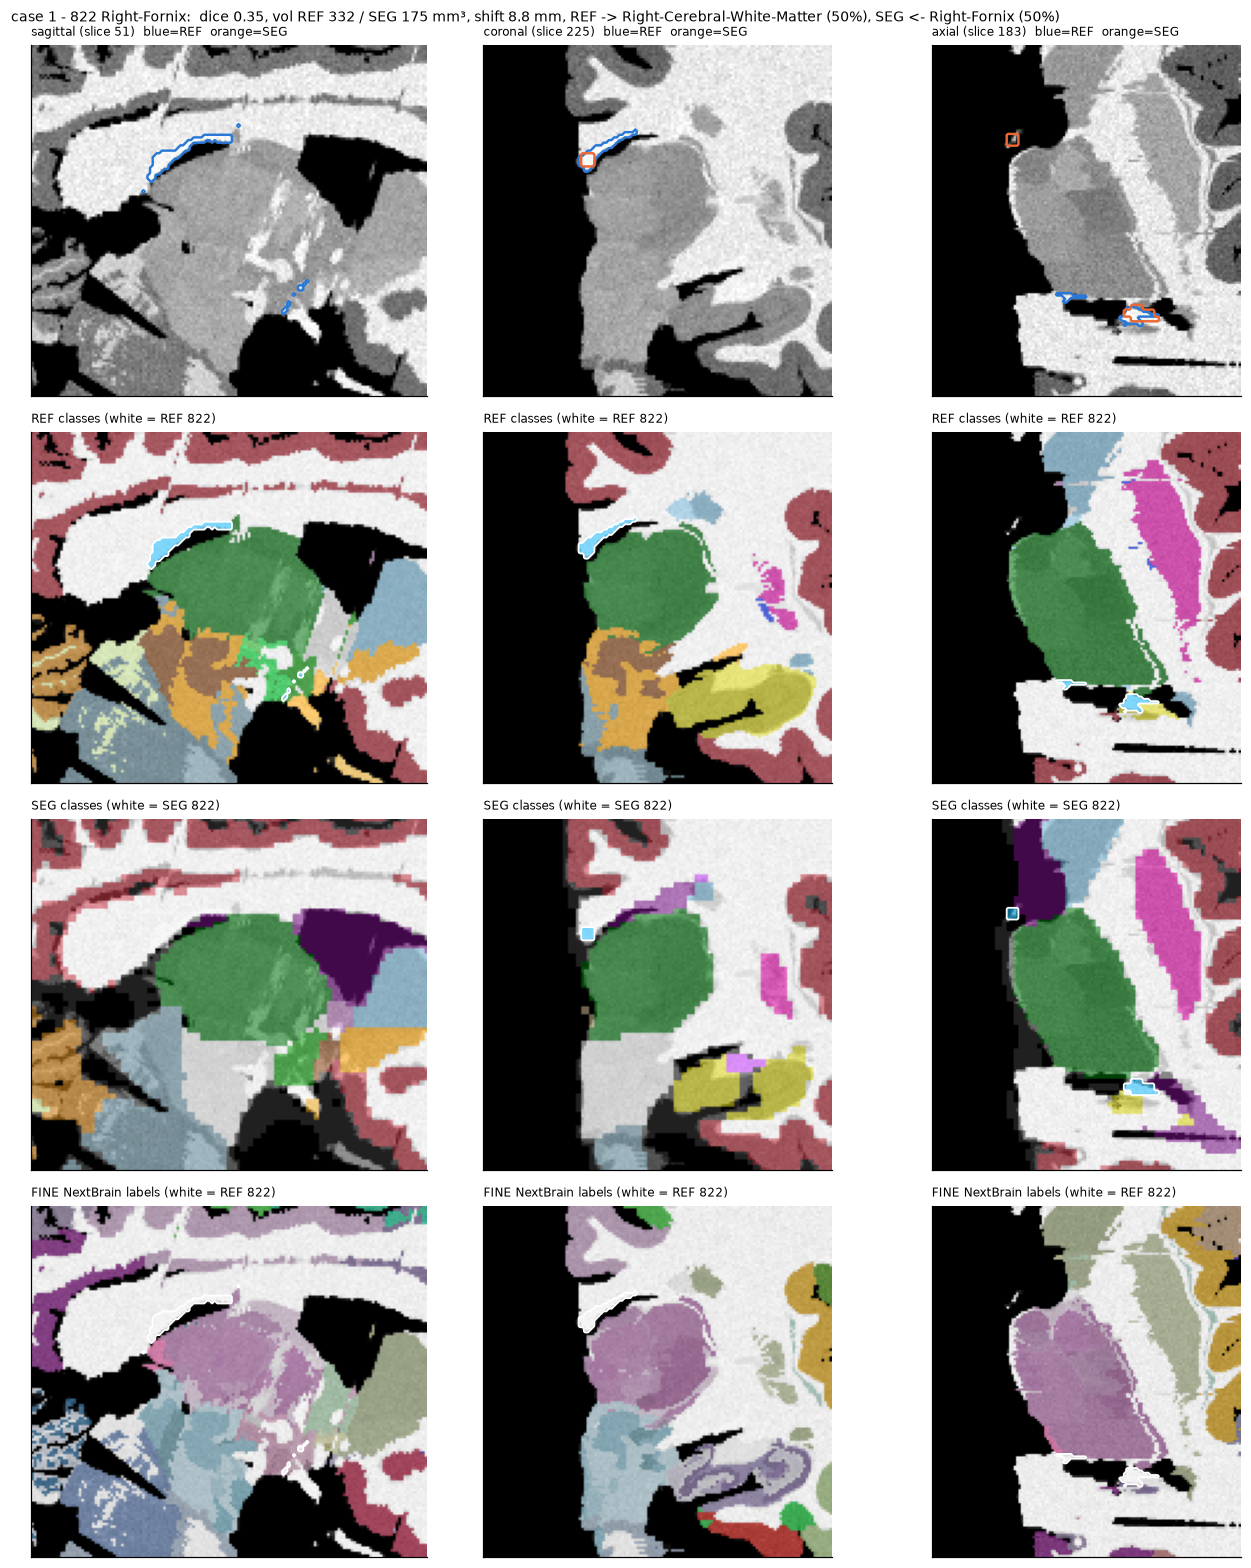

In [11]:
worst = pos.reset_index().head(6)
display(worst[['label', 'name', 'dice', 'shift_mm', 'goes_to', 'comes_from']])
for lab in worst.label:
    lab = int(lab)
    display(Markdown(f'**{lab} {NAMES[lab]}: NextBrain labels it is made of (REF) and what SEG says about them**'))
    display(composition(lab).head(12))
    show_label(1, lab)

### 8.2 SEG-only classes: ventricles and CSF

SuperSynth labels the lateral ventricle (43) and CSF (24), which the converted REF never contains (it is background
there). Shown on case 3 (largest ventricle).

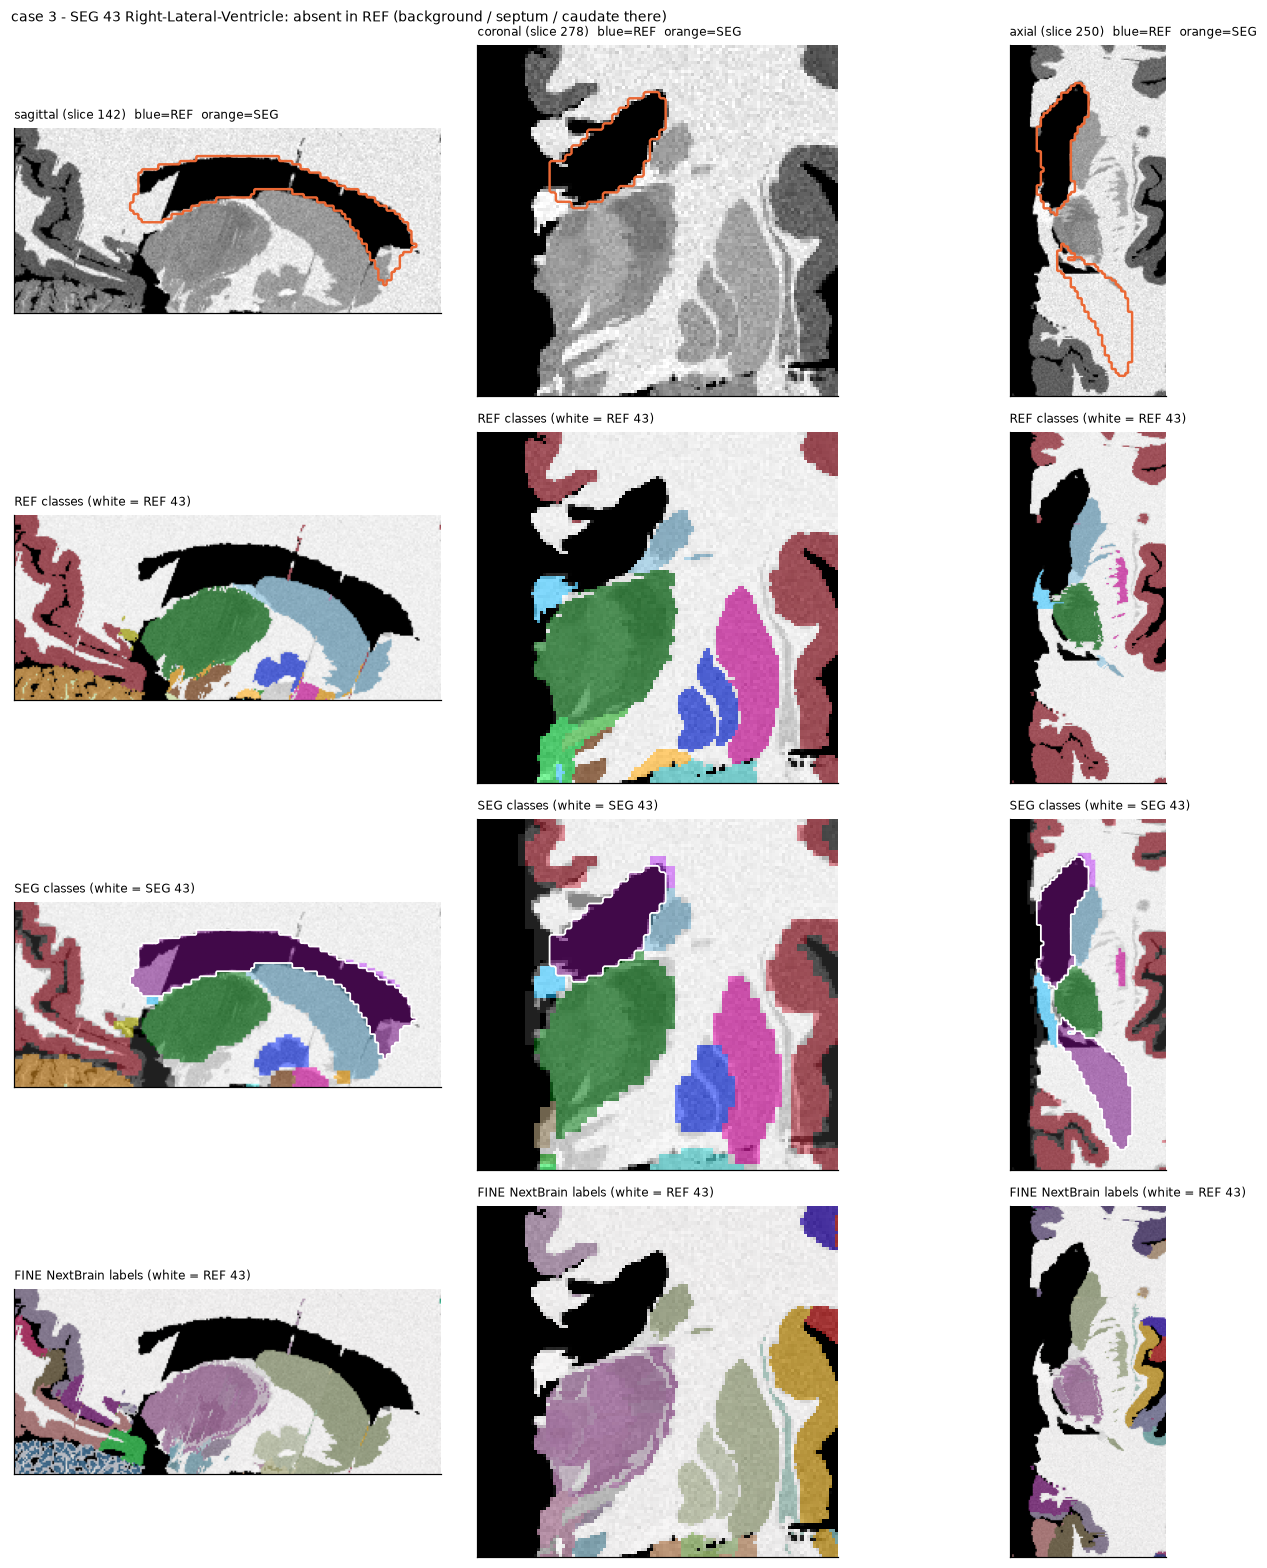

In [12]:
show_label(3, 43, pad_mm=6, title='case 3 - SEG 43 Right-Lateral-Ventricle: absent in REF (background / septum / caudate there)')

### 8.3 Where the two maps disagree (whole hemisphere)

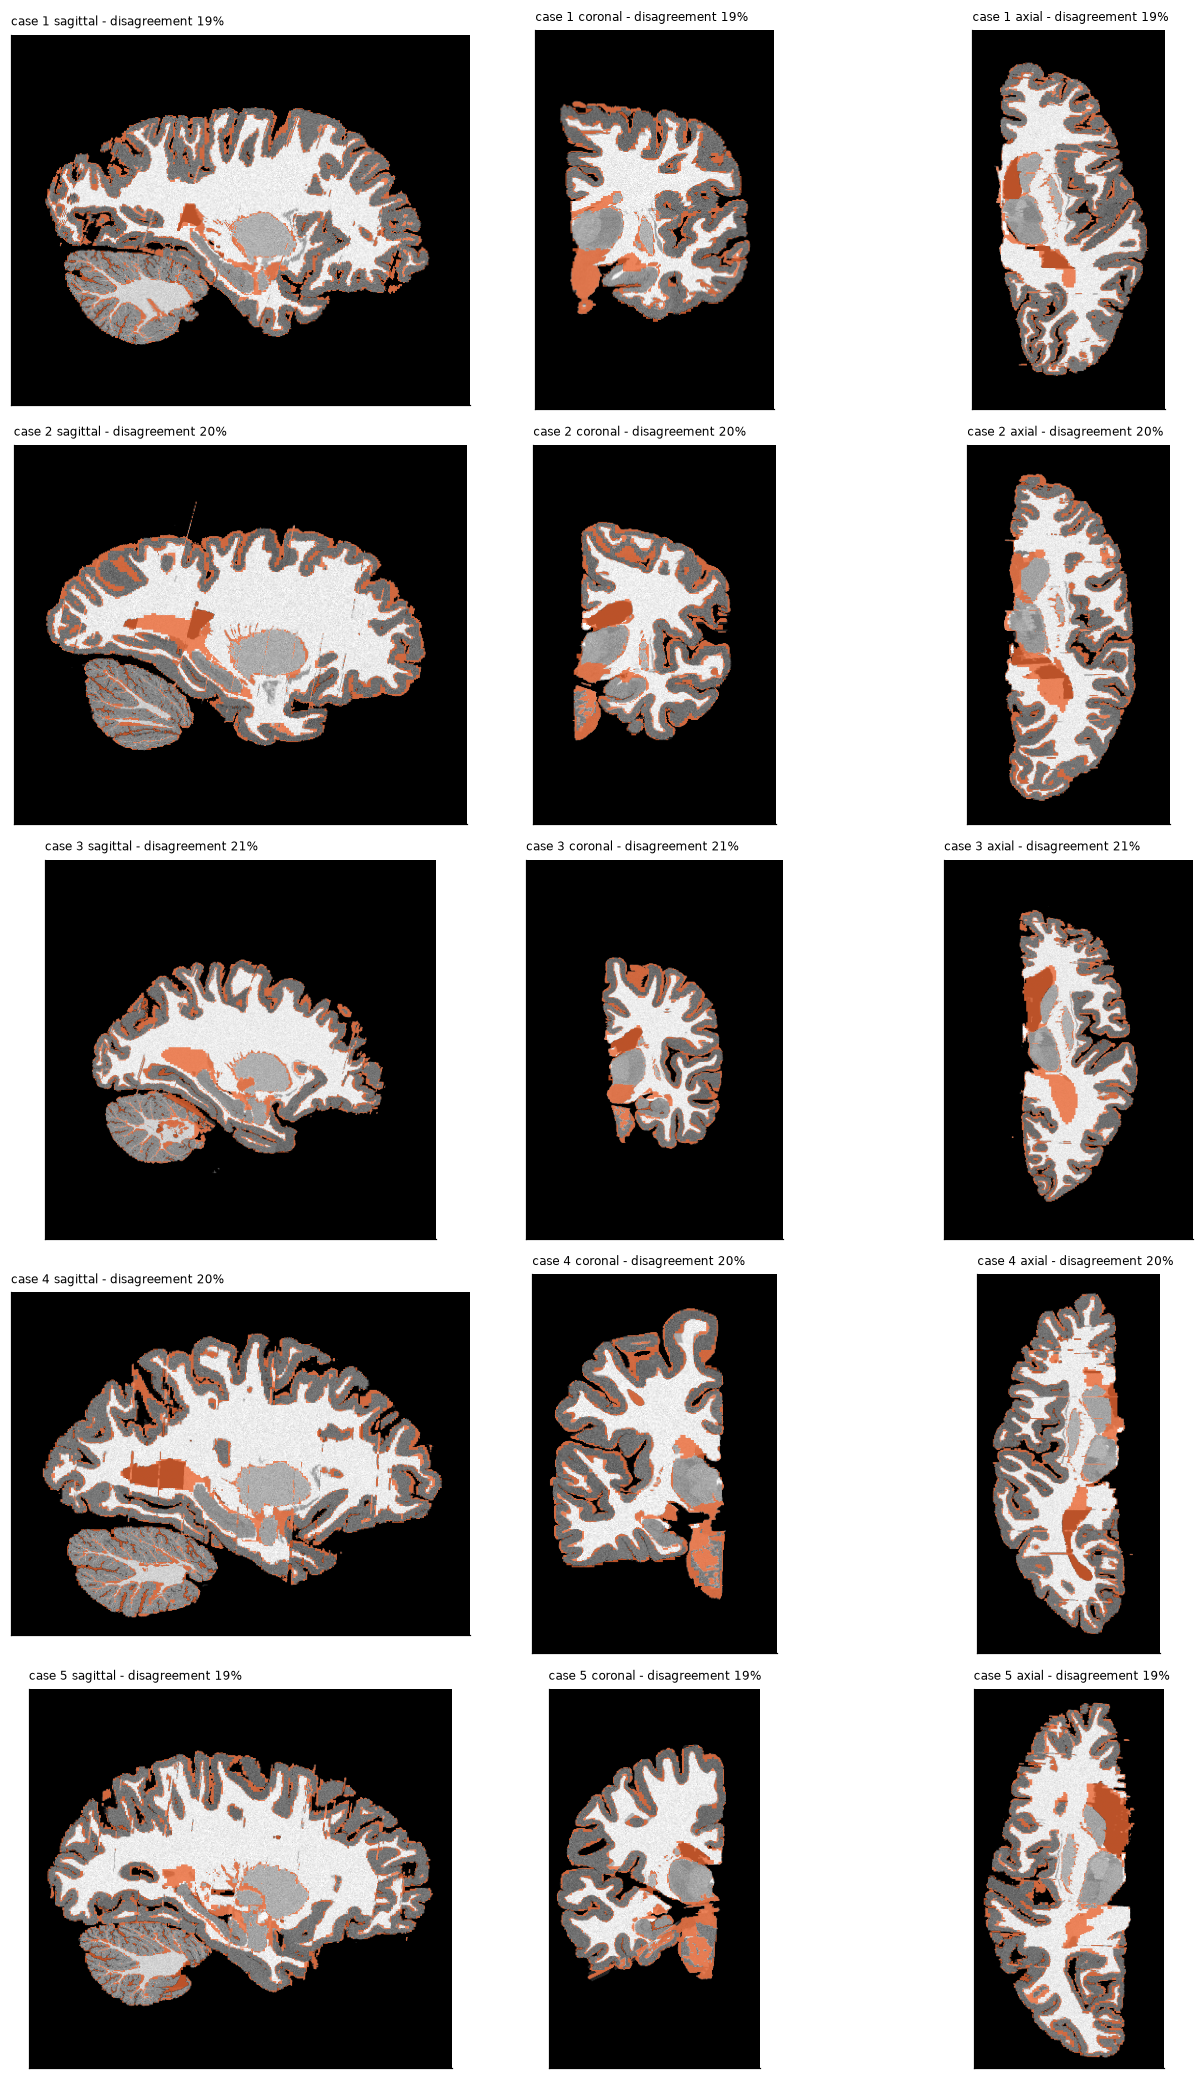

In [13]:
fig, axes = plt.subplots(5, 3, figsize=(12, 19))
for i, case in enumerate(cs.CASES):
    img, ref, seg, _, _ = vols(case)
    fgm = (ref > 0) | ((seg > 0) & ~np.isin(seg, [24, 907, 915]))   # foreground without SEG CSF / non-brain
    c = np.round(np.argwhere(ref > 0).mean(0)).astype(int)
    err = fgm & (ref != seg)
    for j, axis in enumerate(range(3)):
        ax = axes[i, j]
        ax.imshow(_norm(_plane(img, axis, c[axis])), cmap='gray', origin='lower')
        e = _plane(err, axis, c[axis])
        ax.imshow(np.ma.masked_where(~e, e), cmap=mcolors.ListedColormap([C_PRED]), origin='lower', alpha=0.8)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ax.set_title(f'case {case} {["sagittal", "coronal", "axial"][j]} - disagreement {err[fgm].mean():.0%}',
                     fontsize=8, loc='left')
plt.tight_layout(); plt.show()

In orange, voxels where REF and SEG differ. The foreground is REF ∪ SEG, excluding SEG CSF (24) and non-brain tissue (907, 915).

In [14]:
e = conf[conf.ref != conf.pred].copy()
e['ref_name'] = e.ref.map(NAMES.get); e['pred_name'] = e.pred.map(NAMES.get)
e['frac_of_case_error'] = e.n / e.case.map(e.groupby('case').n.sum())
e['vol_mm3'] = e.n * 0.064
top_err = (e.groupby(['ref', 'ref_name', 'pred', 'pred_name']).agg(frac_of_case_error=('frac_of_case_error', 'mean'),
                                                                   vol_mm3=('vol_mm3', 'mean'))
           .sort_values('frac_of_case_error', ascending=False).head(20).reset_index())
top_err.to_csv(METRICS / 'top_confusions.csv', index=False)
display(Markdown('**Top 20 confusions (mean fraction of all disagreeing voxels of a case, mean volume per case)**'))
display(top_err)

**Top 20 confusions (mean fraction of all disagreeing voxels of a case, mean volume per case)**

,ref,ref_name,pred,pred_name,frac_of_case_error,vol_mm3
0,0,background,24,CSF,0.303,49811.610
1,42,Right-Cerebral-Cortex,24,CSF,0.212,33850.163
2,42,Right-Cerebral-Cortex,41,Right-Cerebral-White-Matter,0.105,16938.598
3,41,Right-Cerebral-White-Matter,42,Right-Cerebral-Cortex,0.091,14780.352
4,0,background,42,Right-Cerebral-Cortex,0.046,7720.691
5,0,background,43,Right-Lateral-Ventricle,0.034,5480.115
6,0,background,47,Right-Cerebellum-Cortex,0.032,5196.890
7,41,Right-Cerebral-White-Matter,43,Right-Lateral-Ventricle,0.018,2878.029
8,47,Right-Cerebellum-Cortex,46,Right-Cerebellum-White-Matter,0.016,2680.909
9,46,Right-Cerebellum-White-Matter,47,Right-Cerebellum-Cortex,0.014,2297.920


## 9. Conclusions

(Details with every label id: `comparison_summary.md`.)

1. **Overall agreement.**
   * The large classes agree well. Thalamus 49, white matter 41, putamen 51, cerebellar cortex 47, cortex 42,
     pallidum 52, amygdala 54 and caudate 50 have dice 0.81-0.89. Hippocampus 53 has 0.79.
   * Brain-mask dice is 0.93-0.96, and 73-75 % of the foreground voxels get the same class.
2. **Hemisphere ids.**
   * REF uses `Right-*` ids for all cases. SuperSynth uses `Left-*` for cases 4-5, which are left hemispheres.
   * After harmonising, the side is not a problem: only 0-320 mm³ per case get the ids of the other side.
   * Training on REF together with real SuperSynth labels would need the same harmonisation, or a REF converted with
     the real side (`--side auto`).
3. **SEG-only classes.**
   * REF has no ventricles and no CSF, but SEG labels both:
     * CSF 24: ~88 cm³ per case. ~56 % of it is REF background and ~38 % is REF cortex 42.
     * Lateral ventricle 43: ~9 cm³ per case. ~59 % is REF background inside the brain and ~31 % is REF white matter 41.
     * Smaller ones: 44 Inf-Lat-Vent, 14 and 15 (3rd/4th ventricle), 77 WM-hypointensities.
   * The largest single disagreement is REF cortex 42 -> SEG CSF 24 (~34 cm³ per case, 21 % of all disagreeing
     voxels). This is the same outer-cortex border problem seen with NextBrain.
4. **Mapping problems (section 7).** Several NextBrain labels are put in a SuperSynth class that SuperSynth defines
   differently. In every case, SEG puts none or almost none of their voxels in the REF class, and they explain all
   the low-dice classes:
   * **866 Right-Basal-Forebrain (dice 0.00).** All six of its NextBrain labels are midbrain and subthalamic
     structures: 310 and 352 substantia nigra, 385 red nucleus, 315, 316 and 321 subthalamic nucleus. SEG calls them
     white matter 41 or brainstem 16. SuperSynth's basal forebrain sits elsewhere, where REF has white matter: 120
     ventral pallidus, 108 basal nucleus of Meynert.
   * **58 Right-Accumbens-area (dice 0.26, centroid shift 22 mm).** It contains 384 `midbrain_(mesencephalon)`
     (935 mm³, which SEG calls brainstem), 208 optic tract, 435 ventral tegmental area, 111 diagonal band and 843
     infundibular stalk. Only 101 `core_of_nucleus_accumbens` belongs there.
   * **844 Right-MammillaryBody (dice 0.21).** 275, 297 and 256 (the posterior hypothalamus) are included but
     belong to thalamus or white matter in SEG.
   * **870 Right-SeptalNuc (0.23), 822 Right-Fornix (0.40), 85 Optic-Chiasm (0.34).** SEG puts these partly in the
     lateral ventricle (43) or in CSF (24). 114 optic_nerve is 95 % CSF in SEG.
   * **Smaller ones:** 184 stria_terminalis and 393 tail_of_caudate in Caudate 50; 354 alveus in Hippocampus 53;
     68 septum_pellucidum in white matter 41.
5. **Position.**
   * 1-2 classes per case are misplaced: 866 in every case, and sometimes 844, 870 and 58.
   * No mutual swaps.
   * The large shifts (866: 19 mm, 58: 22 mm) come from the mapping problems in point 4, not from SuperSynth errors.